# Comparación entre localidades

Este cuaderno no vuelve a modelar: lee lo que cada ejecución de `03_localidad.ipynb` guardó en
`resultados.json` y compara las localidades en las decisiones (fuente de irradiancia, imputación), en
los objetivos (rendimiento específico e índice de rendimiento) y en los modelos (validación, prueba,
horizonte diario, pronóstico a 30 días, suficiencia de datos, modelo final y costo). La comparación se guarda
en `comparacion` del mismo archivo. Debajo de cada figura se muestran las primeras filas de sus valores, y el
CSV completo queda en `resultados/datos_figuras/`.

In [1]:
GUARDAR_FIGURAS = True

In [2]:
import os
from pathlib import Path
if not Path("tfm").is_dir() and Path("../tfm").is_dir():
    os.chdir("..")     # copia ejecutada abierta desde notebooks/ejecutados: se trabaja desde notebooks/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown as MarkdownIPython
def Markdown(texto):                  # cifras con coma decimal, como en el documento y las figuras
    return MarkdownIPython(gr.texto_es(texto))
def miles(n):                         # separador de miles con espacio: 12 345 (la coma sería decimal)
    return f"{int(n):,}".replace(",", " ")
from tfm import config, graficos as gr, resultados as res, tiempos
tiempos.activar("comparacion")
gr.estilo()
def fig(f, nombre, datos=None, **kw):
    gr.guardar(f, "comparacion_" + nombre, GUARDAR_FIGURAS, datos, **kw); plt.show()
    if datos is not None:
        gr.mostrar(datos)
    plt.close(f)
R = res.cargar()
LOC = {g: v for g, v in R.get("localidades", {}).items() if isinstance(v, dict) and "conclusiones" in v}
display(Markdown(f"Localidades con resultados completos: **{', '.join(LOC) or 'ninguna'}**"))

Localidades con resultados completos: **G01, G03, G02, G04, G05, G06, G07, G09, G11, G13**

## 1. Decisiones de preprocesamiento por localidad

,unidad_principal,fuente_irradiancia,imputacion,cobertura_satelite_pct,pct_falla_medio,nrmse_h_fuente_elegida,pr_segun_fuente_min,pr_segun_fuente_max
localidad,,,,,,,,
G01,P01I0102,ifs_analisis,lineal,98.873,0.970,24.169,0.705,0.750
G03,P02I0202,ifs_analisis,lineal,98.804,0.936,35.716,0.564,0.658
G02,P04I0202,ifs_analisis,lineal,98.876,8.927,22.556,0.698,0.744
G04,P08I0101,ifs_analisis,lineal,96.659,0.621,31.960,0.757,0.816
G05,P13I0101,ifs_analisis,lineal,98.789,1.191,32.901,0.692,0.779
G06,P05I0101,ifs_analisis,lineal,7.052,0.445,28.018,0.889,0.948
G07,P10I0101,ifs_analisis,lineal,7.026,3.104,26.108,0.732,0.786
G09,P09I0101,ifs_analisis,lineal,98.885,1.362,26.410,0.685,0.784
G11,P14I0101,ifs_analisis,lineal,7.104,0.243,30.698,0.617,0.698


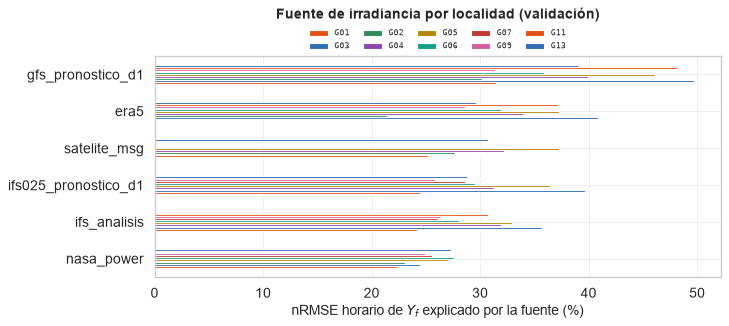

6 filas x 10 columnas; primeras 6:


,G01,G03,G02,G04,G05,G06,G07,G09,G11,G13
nasa_power,22.3154,24.4375,23.1118,33.0297,27.0253,27.6327,25.5840,24.9170,NaN,27.3218
ifs_analisis,24.1692,35.7155,22.5557,31.9600,32.9009,28.0176,26.1083,26.4096,30.6984,27.7549
ifs025_pronostico_d1,24.4176,39.6527,22.9880,31.2371,36.4038,29.5444,28.5641,25.8566,35.1550,28.7996
satelite_msg,25.2030,41.0831,27.6919,32.1837,37.2853,NaN,NaN,26.3101,NaN,30.7094
era5,26.6042,40.9000,21.4428,33.9804,37.2770,31.9398,31.5093,28.6357,37.1928,29.6516
gfs_pronostico_d1,31.4577,49.7423,30.1692,39.9592,46.1089,35.8859,36.7267,31.4042,48.1282,39.0301


In [3]:
filas = []
for g, v in LOC.items():
    c, d = v["conclusiones"], v.get("datos", {})
    fuentes_b = d.get("experimento_fuentes", {}).get("B", {})
    sat = d.get("satelite", {})
    disp = d.get("disponibilidad", {})
    filas.append({"localidad": g, "unidad_principal": c["unidad_principal"], "fuente_irradiancia": c["fuente_irradiancia"],
                  "imputacion": c["imputacion"], "cobertura_satelite_pct": sat.get("cobertura_diurna_pct"),
                  "pct_falla_medio": np.mean([x.get("pct_falla", np.nan) for x in disp.values()]) if disp else np.nan,
                  "nrmse_h_fuente_elegida": fuentes_b.get(c["fuente_irradiancia"], {}).get("nrmse_h_pct"),
                  "pr_segun_fuente_min": min((x.get("pr_ajustado", np.nan) for x in fuentes_b.values()), default=np.nan),
                  "pr_segun_fuente_max": max((x.get("pr_ajustado", np.nan) for x in fuentes_b.values()), default=np.nan)})
DECISIONES = pd.DataFrame(filas).set_index("localidad")
display(DECISIONES.round(3))

# Error de cada fuente para explicar la producción (comparación B) en cada localidad
fb = pd.DataFrame({g: {k: x.get("nrmse_h_pct") for k, x in v.get("datos", {}).get("experimento_fuentes", {}).get("B", {}).items()}
                   for g, v in LOC.items()})
if not fb.empty:
    f, ax = plt.subplots(figsize=(9, 4))
    fb.sort_values(fb.columns[0]).plot.barh(ax=ax)
    ax.set_xlabel("nRMSE horario de Yf explicado por la fuente (%)"); ax.set_title("Fuente de irradiancia por localidad (validación)")
    fig(f, "fuentes_irradiancia", fb)

## 2. Rendimiento específico e índice de rendimiento

In [4]:
obj_filas = []
for g, v in LOC.items():
    for u, e in v.get("objetivos", {}).items():
        obj_filas.append({"localidad": g, "unidad": u, **e})
OBJETIVOS = pd.DataFrame(obj_filas)
display(OBJETIVOS.round(3))

,localidad,unidad,dias,yf_media,yf_mediana,pr_mediano,pr_p10,pr_p90,kstar_mediano
0,G01,P01I0102,487.0,4.321,4.543,0.738,0.583,0.838,0.688
1,G01,P01I0202,485.0,4.092,4.132,0.689,0.542,0.814,0.622
2,G01,P07I0101,217.0,4.496,4.622,0.737,0.598,0.825,0.705
3,G01,P01,481.0,4.249,4.431,0.726,0.581,0.822,0.672
4,G03,P02I0102,393.0,3.191,3.379,0.533,0.424,0.613,0.509
5,G03,P02I0202,393.0,3.113,3.273,0.520,0.424,0.593,0.496
6,G03,P03I0103,83.0,3.524,3.829,0.612,0.452,0.689,0.570
7,G03,P03I0203,81.0,4.048,4.262,0.690,0.524,0.792,0.631
8,G03,P03I0303,80.0,3.945,4.247,0.677,0.512,0.775,0.631
9,G03,P19I0102,65.0,3.773,3.799,0.640,0.383,0.840,0.571


## 3. Pronóstico del día siguiente (H01DH): validación y prueba

**Prueba (2026-09-01 a 2026-10-31), unidad principal de cada localidad**

G01                              G03                  \
                  nrmse_pct skill_vs_cliper   p_dm nrmse_pct skill_vs_cliper   
ML_SVR_E2            29.686           0.179  0.000       NaN             NaN   
SARIMAX_E2_MOS       29.747           0.177  0.000    35.060           0.155   
ML_ENS_E2            30.438           0.158  0.002    34.920           0.158   
K2_LSTM              30.764           0.149  0.015    35.033           0.156   
K1_MLP               31.021           0.142  0.016    36.992           0.108   
SARIMA               32.443           0.103  0.002    39.360           0.051   
ref__cliper          36.159           0.000    NaN    41.488           0.000   
ref__persistencia    43.203          -0.195  0.000    49.179          -0.185   
ML_RF_E2                NaN             NaN    NaN    35.086           0.154   
ML_LGBM_E2              NaN             NaN    NaN       NaN             NaN   
ML_KNN_E2               NaN             NaN    NaN       NaN             NaN   

                               G02                              G04  ...  G07  \
                    p_dm nrmse_pct skill_vs_cliper   p_dm nrmse_pct  ... p_dm   
ML_SVR_E2            NaN       NaN             NaN    NaN       NaN  ...  NaN   
SARIMAX_E2_MOS     0.000    25.849           0.148  0.000    25.530  ...  0.0   
ML_ENS_E2          0.000    26.327           0.132  0.000    25.479  ...  0.0   
K2_LSTM            0.000    32.645          -0.076  0.081    28.446  ...  0.0   
K1_MLP             0.002    43.593          -0.437  0.000    26.888  ...  0.0   
SARIMA             0.128    30.537          -0.007  0.828    26.172  ...  0.0   
ref__cliper          NaN    30.331           0.000    NaN    31.176  ...  NaN   
ref__persistencia  0.000    36.287          -0.196  0.000    33.741  ...  0.0   
ML_RF_E2           0.000       NaN             NaN    NaN    25.400  ...  NaN   
ML_LGBM_E2           NaN    26.921           0.112  0.002       NaN  ...  NaN   
ML_KNN_E2            NaN       NaN             NaN    NaN       NaN  ...  NaN   

                        G09                              G11                  \
                  nrmse_pct skill_vs_cliper   p_dm nrmse_pct skill_vs_cliper   
ML_SVR_E2               NaN             NaN    NaN       NaN             NaN   
SARIMAX_E2_MOS       17.644           0.104  0.021    29.334           0.140   
ML_ENS_E2            17.621           0.105  0.020    32.148           0.058   
K2_LSTM              20.186          -0.025  0.594    31.382           0.080   
K1_MLP               17.652           0.103  0.026    41.455          -0.215   
SARIMA               18.755           0.047  0.243    31.503           0.077   
ref__cliper          19.688           0.000    NaN    34.125           0.000   
ref__persistencia    21.882          -0.111  0.233    35.427          -0.038   
ML_RF_E2             18.039           0.084  0.084       NaN             NaN   
ML_LGBM_E2              NaN             NaN    NaN       NaN             NaN   
ML_KNN_E2               NaN             NaN    NaN       NaN             NaN   

                               G13                         
                    p_dm nrmse_pct skill_vs_cliper   p_dm  
ML_SVR_E2            NaN    38.533           0.173  0.000  
SARIMAX_E2_MOS     0.026    38.331           0.178  0.000  
ML_ENS_E2          0.493    38.942           0.164  0.000  
K2_LSTM            0.611    47.455          -0.018  0.855  
K1_MLP             0.000    42.174           0.095  0.124  
SARIMA             0.140    45.932           0.014  0.819  
ref__cliper          NaN    46.605           0.000    NaN  
ref__persistencia  0.542    53.517          -0.148  0.000  
ML_RF_E2             NaN       NaN             NaN    NaN  
ML_LGBM_E2           NaN       NaN             NaN    NaN  
ML_KNN_E2            NaN       NaN             NaN    NaN  

[11 rows x 30 columns]

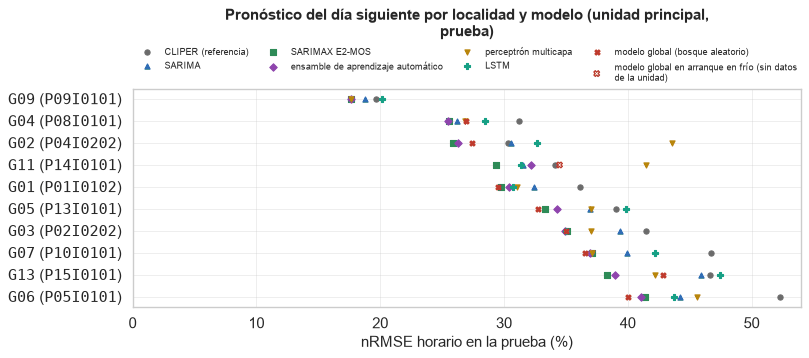

10 filas x 8 columnas; primeras 10:


,ref__cliper,SARIMA,SARIMAX_E2_MOS,ML_ENS_E2,K1_MLP,K2_LSTM,global,global_frio
G09 (P09I0101),19.6880,18.7554,17.6438,17.6210,17.6516,20.1860,NaN,NaN
G04 (P08I0101),31.1762,26.1717,25.5304,25.4793,26.8879,28.4465,26.956,NaN
G02 (P04I0202),30.3306,30.5366,25.8494,26.3274,43.5931,32.6451,27.392,NaN
G11 (P14I0101),34.1248,31.5032,29.3340,32.1485,41.4552,31.3824,NaN,34.485
G01 (P01I0102),36.1588,32.4430,29.7470,30.4383,31.0213,30.7636,29.557,NaN
G05 (P13I0101),39.0271,36.9175,33.3545,34.3090,37.0433,39.8492,32.727,NaN
G03 (P02I0202),41.4885,39.3600,35.0595,34.9195,36.9921,35.0327,34.977,NaN
G07 (P10I0101),46.7345,39.9234,37.1143,36.9206,37.0759,42.1736,36.507,NaN
G13 (P15I0101),46.6050,45.9324,38.3308,38.9415,42.1743,47.4554,42.864,NaN
G06 (P05I0101),52.2859,44.1843,41.4014,41.0835,45.5728,43.7098,40.038,NaN


**Mejor modelo en la prueba por localidad:** G01: ML_SVR_E2; G03: ML_ENS_E2; G02: SARIMAX_E2_MOS; G04: ML_RF_E2; G05: SARIMAX_E2_MOS; G06: ML_ENS_E2; G07: ML_ENS_E2; G09: ML_ENS_E2; G11: SARIMAX_E2_MOS; G13: SARIMAX_E2_MOS

In [5]:
def modelos_de(v, clave_prefijo):
    m = v.get("modelos", {})
    u = v["conclusiones"]["unidad_principal"]
    return m.get(f"{clave_prefijo}_{u}", {})

prueba = {g: pd.DataFrame(modelos_de(v, "prueba_h2")).T for g, v in LOC.items()}
tabla = pd.concat({g: t[["nrmse_pct", "skill_vs_cliper", "p_dm"]] for g, t in prueba.items() if not t.empty}, axis=1)
display(Markdown(f"**Prueba ({config.PARTICIONES['prueba'][0]} a {config.PARTICIONES['prueba'][1]}), unidad principal de cada localidad**")); display(tabla.round(3))
nr = pd.DataFrame({g: t["nrmse_pct"] for g, t in prueba.items() if not t.empty}).astype(float)

def legible(k):
    k = k.replace("ref__", "Ref. ").replace("ML_", "").replace("K1_", "").replace("K2_", "")
    return k.replace("E2_MOS", "E2-MOS").replace("_E2", " E2").replace("_", " ").replace("cliper", "CLIPER")

# Una fila por localidad (su unidad principal) y un punto por modelo, con el modelo global en la misma unidad.
# El global se evalúa en las horas de la prueba en que tiene todas sus entradas, que no son exactamente las
# mismas que las del cuaderno de cada localidad: la comparación formal con Diebold-Mariano esta en tfm_global.
SERIES = [("ref__cliper", "CLIPER (referencia)"), ("SARIMA", "SARIMA"), ("SARIMAX_E2_MOS", "SARIMAX E2-MOS"),
          ("ML_ENS_E2", "ensamble de aprendizaje automático"), ("K1_MLP", "perceptrón multicapa"), ("K2_LSTM", "LSTM")]
glob = R.get("global", {}).get("prueba", {}).get("nrmse_por_unidad", {})
# Unidades sin entrenamiento en el panel: el global se evalúa como arranque en frío (nunca las vio)
frio = R.get("global", {}).get("arranque_en_frio", {}).get("nrmse_por_unidad", {})
elegido_g = R.get("global", {}).get("validacion", {}).get("elegido", "RF")
filas_g = {}
for g, v in LOC.items():
    u = v["conclusiones"]["unidad_principal"]
    fila = {k: nr.loc[k, g] if k in nr.index and g in nr.columns else np.nan for k, _ in SERIES}
    fila["global"] = glob.get(u, {}).get(elegido_g, np.nan)
    fila["global_frio"] = frio.get(u, {}).get(elegido_g, np.nan)
    filas_g[f"{g} ({u})"] = fila
GR = pd.DataFrame(filas_g).T.sort_values("SARIMAX_E2_MOS")
estilos = gr.estilos_series(len(SERIES) + 1)
f, ax = plt.subplots(figsize=(10, 0.28 * len(GR) + 1.6))
yy = np.arange(len(GR))
for (k, nombre), e in zip(SERIES + [("global", "modelo global (bosque aleatorio)")], estilos):
    color = config.COLOR_NEUTRO if k.startswith("ref") else e["color"]
    ax.scatter(GR[k], yy, s=22, color=color, marker=e["marker"], label=nombre, zorder=3)
    if k == "global" and GR["global_frio"].notna().any():
        ax.scatter(GR["global_frio"], yy, s=26, facecolors="none", edgecolors=color, linewidths=1.2,
                   marker=e["marker"], label="modelo global en arranque en frío (sin datos de la unidad)", zorder=3)
ax.set_yticks(yy, GR.index, fontsize=8); ax.invert_yaxis()
ax.set_xlim(left=0); ax.set_xlabel("nRMSE horario en la prueba (%)")
ax.set_title("Pronóstico del día siguiente por localidad y modelo (unidad principal, prueba)")
ax.legend(fontsize=7, ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.07), frameon=False)
nr = GR
fig(f, "prueba_h2", nr)
mejores = {g: t.drop(index=[i for i in t.index if i.startswith("ref")])["nrmse_pct"].astype(float).idxmin() for g, t in prueba.items() if not t.empty}
display(Markdown("**Mejor modelo en la prueba por localidad:** " + "; ".join(f"{g}: {m}" for g, m in mejores.items())))

### 3.1 Qué familia de modelos funciona mejor en cada localidad

El mapa de calor resume el *skill* frente a CLIPER en la prueba (unidad principal de cada localidad): en naranja, de
claro a oscuro, los modelos que mejoran a la referencia; en gris, los que no la mejoran. El asterisco marca una
diferencia significativa con Diebold-Mariano (p < 0,05). Las barras dan el nRMSE mediano de cada familia en las
localidades, con las referencias como líneas: en naranja las familias que mejoran a CLIPER con significancia en al
menos la mitad de las localidades.

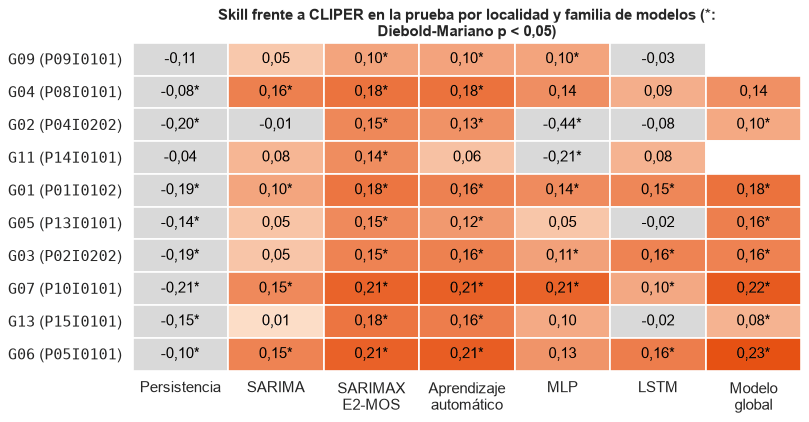

10 filas x 7 columnas; primeras 10:


,Persistencia,SARIMA,SARIMAX E2-MOS,Aprendizaje automático,MLP,LSTM,Modelo global
G09 (P09I0101),-0.1115,0.0474,0.1038,0.1050,0.1034,-0.0253,NaN
G04 (P08I0101),-0.0823,0.1605,0.1811,0.1827,0.1376,0.0876,0.1354
G02 (P04I0202),-0.1964,-0.0068,0.1477,0.1320,-0.4373,-0.0763,0.0969
G11 (P14I0101),-0.0382,0.0768,0.1404,0.0579,-0.2148,0.0804,NaN
G01 (P01I0102),-0.1948,0.1028,0.1773,0.1582,0.1421,0.1492,0.1826
G05 (P13I0101),-0.1400,0.0541,0.1454,0.1209,0.0508,-0.0211,0.1614
G03 (P02I0202),-0.1854,0.0513,0.1550,0.1583,0.1084,0.1556,0.1569
G07 (P10I0101),-0.2088,0.1457,0.2058,0.2100,0.2067,0.0976,0.2188
G13 (P15I0101),-0.1483,0.0144,0.1775,0.1644,0.0951,-0.0182,0.0803
G06 (P05I0101),-0.1042,0.1550,0.2082,0.2142,0.1284,0.1640,0.2342


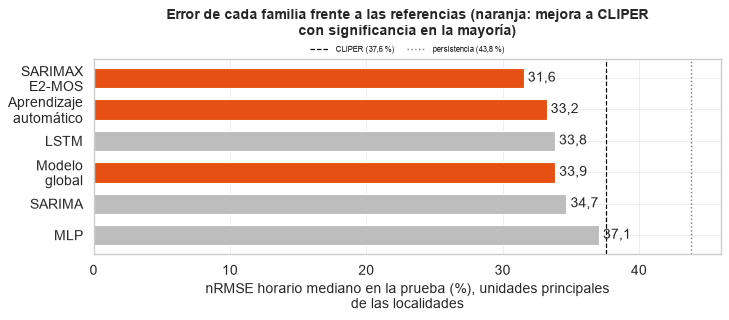

8 filas x 2 columnas; primeras 8:


,nrmse_mediano,mejora_mayoria
Aprendizaje automático,33.2288,True
CLIPER,37.5930,NaN
LSTM,33.8389,False
MLP,37.0596,False
Modelo global,33.8520,True
Persistencia,43.8474,NaN
SARIMA,34.6802,False
SARIMAX E2-MOS,31.5508,True


In [6]:
FAM = [("ref__persistencia", "Persistencia"), ("SARIMA", "SARIMA"), ("SARIMAX_E2_MOS", "SARIMAX E2-MOS"),
       ("ML_ENS_E2", "Aprendizaje automático"), ("K1_MLP", "MLP"), ("K2_LSTM", "LSTM"), ("global", "Modelo global")]
SK = pd.DataFrame(np.nan, index=GR.index, columns=[n for _, n in FAM])
SIG = pd.DataFrame(False, index=GR.index, columns=SK.columns)
NR = pd.DataFrame(np.nan, index=GR.index, columns=["CLIPER"] + [n for _, n in FAM])
TAB_G = R.get("global", {}).get("vs_individual", {}).get("tabla", {})     # contraste del global con CLIPER por unidad
for g, v in LOC.items():
    u = v["conclusiones"]["unidad_principal"]
    fila, tp = f"{g} ({u})", prueba.get(g)
    if fila not in SK.index or tp is None or tp.empty:
        continue
    c = float(tp.loc["ref__cliper", "nrmse_pct"]) if "ref__cliper" in tp.index else np.nan
    NR.loc[fila, "CLIPER"] = c
    for k, nombre in FAM:
        if k == "global":
            gl = GR.loc[fila, "global"]
            NR.loc[fila, nombre] = gl
            SK.loc[fila, nombre] = 1 - gl / c if np.isfinite(gl) and np.isfinite(c) and c > 0 else np.nan
            pv = TAB_G.get(u, {}).get("p_vs_cliper")
            SIG.loc[fila, nombre] = bool(pv is not None and np.isfinite(pv) and pv < 0.05)
        elif k in tp.index:
            NR.loc[fila, nombre] = float(tp.loc[k, "nrmse_pct"])
            SK.loc[fila, nombre] = float(tp.loc[k, "skill_vs_cliper"])
            pv = tp.loc[k, "p_dm"] if "p_dm" in tp.columns else np.nan
            SIG.loc[fila, nombre] = bool(pd.notna(pv) and float(pv) < 0.05)
# Mapa de calor: naranja (escala secuencial de un solo tono) si mejora a CLIPER, gris si no
from matplotlib.colors import LinearSegmentedColormap
naranja = LinearSegmentedColormap.from_list("naranja_viu", ["#FDE6D2", config.COLOR_PRINCIPAL])
vmax = max(0.05, float(np.nanmax(SK.to_numpy())) if np.isfinite(SK.to_numpy()).any() else 0.05)
f, ax = plt.subplots(figsize=(10, 0.34 * len(SK) + 1.8))
for i, fila in enumerate(SK.index):
    for j, col in enumerate(SK.columns):
        val = SK.loc[fila, col]
        color = "#FFFFFF" if not np.isfinite(val) else ("#D9D9D9" if val <= 0 else naranja(min(1.0, val / vmax)))
        ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor=color, edgecolor="white", lw=1.5))
        if np.isfinite(val):
            txt = f"{val:.2f}".replace(".", ",") + ("*" if SIG.loc[fila, col] else "")
            ax.text(j, i, txt, ha="center", va="center", color="black")
ax.set_xlim(-0.5, len(SK.columns) - 0.5); ax.set_ylim(len(SK) - 0.5, -0.5)
# Rótulos horizontales, partidos en dos líneas cuando son largos
ax.set_xticks(range(len(SK.columns)), [gr.partir(c, 12) for c in SK.columns], rotation=0, ha="center")
ax.set_yticks(range(len(SK)), SK.index)
ax.set_title("Skill frente a CLIPER en la prueba por localidad y familia de modelos (*: Diebold-Mariano p < 0,05)")
for s in ax.spines.values():
    s.set_visible(False)
fig(f, "skill_localidad_modelo", SK.round(4))
# Barras: nRMSE mediano por familia y líneas de referencia
med = NR.median()
fam = [n for _, n in FAM if n != "Persistencia"]
mejora = {n: (SIG[n] & (SK[n] > 0)).sum() >= 0.5 * SK[n].notna().sum() if n in SIG else False for n in fam}
orden = med[fam].sort_values()
f, ax = plt.subplots(figsize=(9, 0.42 * len(orden) + 1.4))
ax.barh(range(len(orden)), orden.to_numpy(), color=[config.COLOR_PRINCIPAL if mejora.get(n) else "#BDBDBD" for n in orden.index], height=0.65)
ax.axvline(med["CLIPER"], color="black", ls="--", lw=1.1, label=f"CLIPER ({med['CLIPER']:.1f} %)".replace(".", ","))
ax.axvline(med["Persistencia"], color="#7F7F7F", ls=":", lw=1.3, label=f"persistencia ({med['Persistencia']:.1f} %)".replace(".", ","))
for i, v in enumerate(orden.to_numpy()):
    ax.text(v + 0.3, i, f"{v:.1f}".replace(".", ","), va="center")
ax.set_yticks(range(len(orden)), [gr.partir(n, 12) for n in orden.index]); ax.invert_yaxis()
ax.set_xlabel("nRMSE horario mediano en la prueba (%), unidades principales de las localidades")
ax.set_title("Error de cada familia frente a las referencias (naranja: mejora a CLIPER con significancia en la mayoría)")
# Leyenda abajo a la izquierda, fuera del eje: dentro taparia las barras más largas
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.22), ncol=2)
fig(f, "nrmse_familias", pd.DataFrame({"nrmse_mediano": med, "mejora_mayoria": pd.Series(mejora)}))
res.registrar("comparacion.skill_localidad_modelo", SK.round(4).replace({np.nan: None}).to_dict(orient="index"))

### 3.2 La flota en cajas: depuración, modelo individual y modelo global

Dos paneles con la distribución del nRMSE horario de la prueba entre las unidades, cada uno en una muestra común. A la
izquierda, el costo de no depurar (cuaderno de calidad de la flota): el mismo SARIMAX E2-MOS entrenado con todo el
histórico sin ningún régimen (T), con el último régimen de capacidad sin excluir las horas recortadas (A) y
con el régimen vigente depurado (B), evaluados en las mismas horas limpias de cada
unidad; una línea une los valores de cada unidad. A la derecha, en las horas comunes de la prueba de cada unidad (cuaderno del
modelo global): CLIPER, el SARIMAX E2-MOS individual, el modelo global con la unidad en el entrenamiento y el global
con su planta fuera del entrenamiento, que es lo que tendría una planta nueva el primer día.

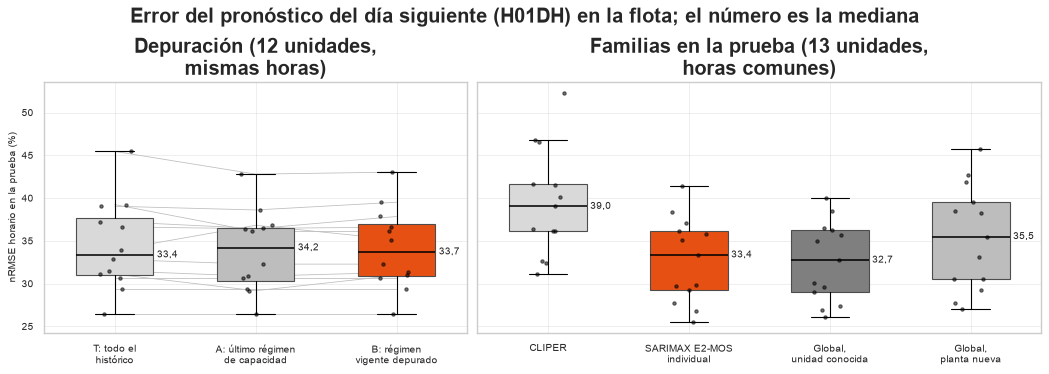

13 filas x 7 columnas; primeras 10:


ablacion                 familias                                     \
          nrmse_T nrmse_A nrmse_B   cliper sarimax_individual global_conocida   
P01I0102   29.383  29.383  29.383   36.159             29.747          29.557   
P01I0202   30.600  30.600  30.600   36.111             29.787          30.049   
P02I0102   37.243  36.454  36.600   41.628             36.195          35.678   
P02I0202   36.636  36.416  37.844   41.488             35.060          34.998   
P04I0102   31.486  30.863  31.302   32.610             26.826          26.041   
P04I0202   32.819  32.276  32.275   32.411             27.741          27.392   
P05I0101   45.457  42.793  43.035   52.286             41.401          40.038   
P07I0101   31.110  29.167  30.967   36.350             29.200          29.040   
P08I0101   26.455  26.455  26.455   31.176             25.530          26.956   
P10I0101   39.040  38.607  39.514   46.735             37.114          36.507   

                              
         global_planta_nueva  
P01I0102              30.589  
P01I0202              30.563  
P02I0102              42.653  
P02I0202              45.786  
P04I0102              27.077  
P04I0202              27.704  
P05I0101              41.926  
P07I0101              29.235  
P08I0101              35.497  
P10I0101              39.579

In [7]:
ABL_C = pd.DataFrame(R.get("flota", {}).get("recorte", {}).get("ablacion", {})).T
COLS_ABL = [c for c in ("nrmse_T", "nrmse_A", "nrmse_B") if c in ABL_C.columns] if len(ABL_C) else ["nrmse_A", "nrmse_B"]
ABL_C = (ABL_C.reindex(columns=COLS_ABL).apply(pd.to_numeric, errors="coerce").dropna()
         if len(ABL_C) else pd.DataFrame(columns=COLS_ABL))
CAJ = pd.DataFrame(R.get("global", {}).get("cajas_flota", {}).get("por_unidad", {})).T
COLS_CAJ = {"cliper": "CLIPER", "sarimax_individual": "SARIMAX E2-MOS\nindividual", "global_conocida": "Global,\nunidad conocida",
            "global_planta_nueva": "Global,\nplanta nueva"}
CAJ = CAJ.reindex(columns=list(COLS_CAJ)).apply(pd.to_numeric, errors="coerce").dropna() if len(CAJ) else pd.DataFrame(columns=list(COLS_CAJ))
COLOR_CAJ = {"cliper": "#D9D9D9", "sarimax_individual": config.COLOR_PRINCIPAL, "global_conocida": "#7F7F7F", "global_planta_nueva": "#BDBDBD"}
if len(ABL_C) or len(CAJ):
    f, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True, gridspec_kw={"width_ratios": [len(COLS_ABL), 4]})
    def cajas(ax, datos, colores, rotulos):
        cj = ax.boxplot([datos[c].to_numpy() for c in datos.columns], positions=range(len(datos.columns)), widths=0.55,
                        patch_artist=True, showfliers=False, medianprops={"color": "black", "lw": 1.4})
        for caja, c in zip(cj["boxes"], datos.columns):
            caja.set_facecolor(colores[c]); caja.set_edgecolor("#4D4D4D")
        rng = np.random.default_rng(config.SEMILLA)
        for j, c in enumerate(datos.columns):
            ax.scatter(j + rng.uniform(-0.12, 0.12, len(datos)), datos[c], s=9, color="black", alpha=0.55, zorder=3)
            ax.annotate(f"{datos[c].median():.1f}".replace(".", ","), (j + 0.3, datos[c].median()), fontsize=8.5, va="center")
        ax.set_xticks(range(len(datos.columns)), [rotulos[c] for c in datos.columns], fontsize=9)
    if len(ABL_C):
        for _, r in ABL_C.iterrows():
            ax_a.plot(range(len(COLS_ABL)), [r[c] for c in COLS_ABL], color="#BDBDBD", ls="-", lw=0.7, zorder=1)
        cajas(ax_a, ABL_C, {"nrmse_T": "#D9D9D9", "nrmse_A": "#BDBDBD", "nrmse_B": config.COLOR_PRINCIPAL},
              {"nrmse_T": "T: todo el\nhistórico", "nrmse_A": "A: último régimen\nde capacidad",
               "nrmse_B": "B: régimen\nvigente depurado"})
        ax_a.set_title(f"Depuración ({len(ABL_C)} unidades, mismas horas)", fontsize=10)
    if len(CAJ):
        cajas(ax_b, CAJ, COLOR_CAJ, COLS_CAJ)
        ax_b.set_title(f"Familias en la prueba ({len(CAJ)} unidades, horas comunes)", fontsize=10)
    ax_a.set_ylabel("nRMSE horario en la prueba (%)")
    f.suptitle("Error del pronóstico del día siguiente (H01DH) en la flota; el número es la mediana", fontsize=11)
    fig(f, "cajas_flota", pd.concat({"ablacion": ABL_C, "familias": CAJ}, axis=1), escala_ejes=0.5, escala_textos=0.5)
    res.registrar("comparacion.cajas_flota", {
        "unidades_ablacion": int(len(ABL_C)), "unidades_familias": int(len(CAJ)),
        "mediana_A": float(ABL_C["nrmse_A"].median()) if len(ABL_C) else None,
        "mediana_B": float(ABL_C["nrmse_B"].median()) if len(ABL_C) else None,
        "mediana_A_menos_B": float((ABL_C["nrmse_A"] - ABL_C["nrmse_B"]).median()) if len(ABL_C) else None,
        "mediana_T": float(ABL_C["nrmse_T"].median()) if "nrmse_T" in ABL_C and len(ABL_C) else None,
        "mediana_T_menos_B": float((ABL_C["nrmse_T"] - ABL_C["nrmse_B"]).median()) if "nrmse_T" in ABL_C and len(ABL_C) else None,
        "medianas_familias": CAJ.median().round(3).to_dict() if len(CAJ) else {}})
else:
    display(Markdown("Sin datos para las cajas de la flota todavía (los escriben el cuaderno de calidad de la flota y el global)."))

## 4. Horizonte diario (H07DD) y suficiencia de datos

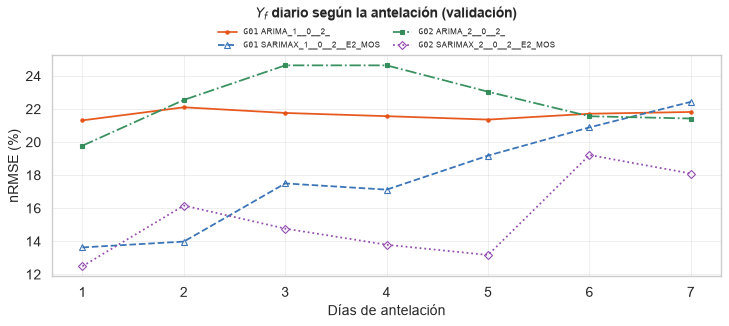

7 filas x 20 columnas; primeras 7:


,G01 ARIMA_1__0__2_,G01 SARIMAX_1__0__2__E2_MOS,G03 ARIMA_1__0__2_,G03 SARIMAX_1__0__2__E2_MOS,G02 ARIMA_2__0__2_,G02 SARIMAX_2__0__2__E2_MOS,G04 ARIMA_1__0__2_,G04 SARIMAX_1__0__2__E2_MOS,G05 ARIMA_1__0__0_,G05 SARIMAX_1__0__0__E2_MOS,G06 ARIMA_0__0__1_,G06 SARIMAX_0__0__1__E2_MOS,G07 ARIMA_2__0__0_,G07 SARIMAX_2__0__0__E2_MOS,G09 ARIMA_2__0__0_,G09 SARIMAX_2__0__0__E2_MOS,G11 ARIMA_0__0__2_,G11 SARIMAX_0__0__2__E2_MOS,G13 ARIMA_1__0__0_,G13 SARIMAX_1__0__0__E2_MOS
1,21.318,13.633,18.617,11.532,19.785,12.493,20.312,17.234,21.092,14.264,17.797,17.339,21.086,16.779,19.267,15.943,20.897,18.881,28.849,23.225
2,22.107,13.986,21.053,14.954,22.553,16.165,21.980,18.237,23.953,14.862,17.296,18.461,21.289,17.462,23.061,19.157,21.552,20.118,30.368,24.534
3,21.765,17.503,20.747,17.172,24.645,14.769,22.104,18.730,22.925,16.322,17.296,19.874,20.230,19.131,24.515,21.025,21.367,23.449,30.576,23.711
4,21.571,17.127,20.553,18.144,24.645,13.794,22.234,18.757,22.620,17.174,17.296,21.252,20.934,20.118,23.962,22.006,21.367,22.246,30.577,23.941
5,21.364,19.187,20.464,19.234,23.049,13.175,21.958,19.950,21.803,17.921,17.296,21.113,21.095,20.084,23.568,24.001,21.367,22.082,30.562,22.892
6,21.718,20.894,20.600,22.624,21.565,19.222,21.496,20.527,21.274,19.913,17.296,23.407,21.241,21.199,23.846,19.634,21.367,24.465,30.594,24.402
7,21.826,22.439,20.663,23.864,21.429,18.099,20.873,21.100,21.359,21.190,17.296,23.265,21.071,21.112,24.247,21.879,21.367,24.012,30.600,25.453


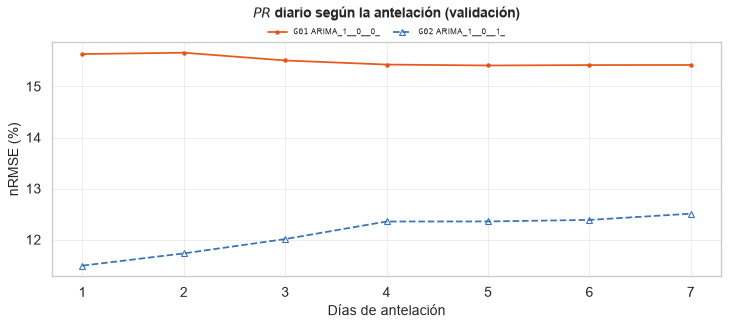

7 filas x 10 columnas; primeras 7:


,G01 ARIMA_1__0__0_,G03 ARIMA_2__0__1_,G02 ARIMA_1__0__1_,G04 ARIMA_2__0__1_,G05 ARIMA_1__0__2_,G06 ARIMA_1__0__0_,G07 ARIMA_1__0__1_,G09 ARIMA_2__0__0_,G11 ARIMA_0__0__1_,G13 ARIMA_2__0__0_
1,15.635,12.336,11.490,19.425,21.184,14.447,10.955,13.329,11.441,24.607
2,15.661,12.736,11.730,19.328,20.697,13.769,10.717,15.287,11.410,23.829
3,15.509,12.615,12.011,19.330,20.588,13.702,10.726,18.010,11.410,24.165
4,15.429,12.515,12.355,19.344,20.380,13.836,10.849,18.524,11.410,24.358
5,15.411,12.526,12.356,19.306,18.232,13.816,10.707,19.029,11.410,24.255
6,15.419,12.617,12.386,19.206,16.555,13.837,10.858,19.686,11.410,24.493
7,15.421,12.755,12.508,19.098,16.456,13.841,10.823,20.604,11.410,24.594


**G01, suficiencia de datos (nRMSE en validación)**

,ML_SVR,SARIMAX_E2_MOS
7,55.29,54.24
14,56.23,24.18
30,32.91,23.91
60,25.60,23.28
90,24.01,23.34
180,23.74,22.77
365,22.59,23.15
todo,22.33,23.04


**G03, suficiencia de datos (nRMSE en validación)**

,ML_RF,SARIMAX_E2_MOS
7,38.00,65.73
14,21.74,20.97
30,21.61,20.68
60,20.16,20.34
90,20.70,20.34
180,19.44,20.85
365,19.51,21.06
todo,19.51,20.68


... (12 outputs left out)

**G11, suficiencia de datos (nRMSE en validación)**

,ML_ENS,SARIMAX_E2_MOS
7,38.88,34.16
14,33.25,32.55
30,33.05,33.66
60,32.66,33.95
90,32.66,33.51
180,32.66,33.09
365,32.66,32.99
todo,32.66,32.99


**G13, suficiencia de datos (nRMSE en validación)**

,ML_SVR,SARIMAX_E2_MOS
7,63.26,45.83
14,56.77,46.06
30,53.59,49.36
60,46.80,47.97
90,46.47,46.45
180,46.47,45.71
365,46.47,45.26
todo,46.47,45.26


In [8]:
for objetivo in ("yf", "pr"):
    cols = {}
    for g, v in LOC.items():
        h3 = modelos_de(v, "h3").get(objetivo, {})
        for modelo, por_h in h3.items():
            if modelo.startswith("ref") and modelo not in ("ref: cliper",):
                continue
            s = pd.Series(por_h).astype(float); s.index = s.index.astype(int)
            cols[f"{g} {modelo}"] = s
    if cols:
        T3 = pd.DataFrame(cols).sort_index()
        # Figura de las dos localidades en detalle (no caben más series con colores distinguibles); valores de todas
        T3g = T3[[c for c in T3.columns if c.split(" ")[0] in ("G01", "G02")]]
        T3g = T3g.iloc[:, :len(config.PALETA)]
        fig(gr.lineas(T3g, f"{'Yf' if objetivo == 'yf' else 'PR'} diario según la antelación (validación)", "Días de antelación", "nRMSE (%)"),
            f"h3_{objetivo}", T3)

suf = {g: modelos_de(v, "suficiencia") for g, v in LOC.items()}
for g, s in suf.items():
    if s:
        display(Markdown(f"**{g}, suficiencia de datos (nRMSE en validación)**")); display(pd.DataFrame(s["nrmse_pct"]).round(2))

## 5. Pronóstico diario a 30 días

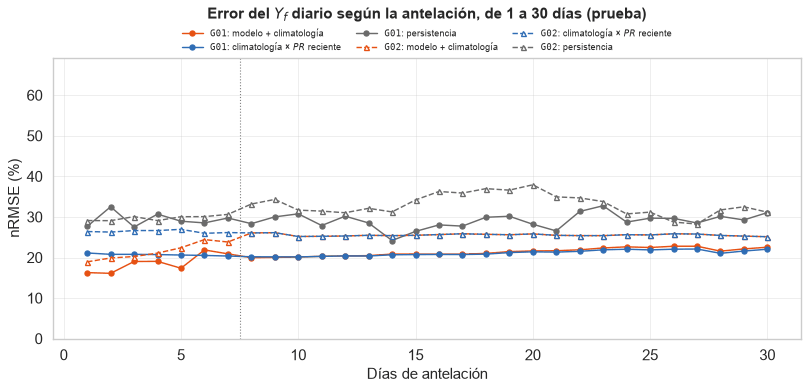

30 filas x 30 columnas; primeras 10:


,G01 modelo_y_climatologia,G01 climatologia_por_PR_reciente,G01 persistencia,G03 modelo_y_climatologia,G03 climatologia_por_PR_reciente,G03 persistencia,G02 modelo_y_climatologia,G02 climatologia_por_PR_reciente,G02 persistencia,G04 modelo_y_climatologia,...,G07 persistencia,G09 modelo_y_climatologia,G09 climatologia_por_PR_reciente,G09 persistencia,G11 modelo_y_climatologia,G11 climatologia_por_PR_reciente,G11 persistencia,G13 modelo_y_climatologia,G13 climatologia_por_PR_reciente,G13 persistencia
1,16.280,21.121,27.660,19.435,25.860,29.985,18.936,26.403,29.110,7.003,...,39.347,9.040,10.532,9.968,17.875,15.011,17.756,21.493,24.493,35.728
2,16.101,20.785,32.507,19.949,25.972,38.402,19.884,26.270,29.084,5.888,...,37.297,9.719,10.811,12.564,20.217,14.375,22.107,18.959,23.939,39.978
3,19.019,20.781,27.522,21.897,26.141,40.979,20.241,26.650,30.082,7.513,...,36.382,10.636,10.881,13.526,23.119,13.116,19.266,19.695,24.264,41.925
4,19.054,20.724,30.693,23.249,26.300,37.906,21.093,26.646,29.095,10.169,...,42.604,11.513,11.081,13.682,24.093,12.891,21.061,19.935,23.549,30.829
5,17.359,20.613,28.946,22.904,26.634,33.641,22.401,26.945,30.052,4.138,...,39.659,12.932,11.322,13.865,24.465,12.792,21.150,23.244,23.919,30.663
6,21.870,20.516,28.533,27.008,26.837,35.706,24.418,25.970,30.077,11.513,...,35.023,16.025,11.559,13.849,25.589,13.407,23.016,27.181,23.820,34.011
7,20.909,20.365,29.740,26.358,26.920,34.110,23.825,26.149,30.628,5.427,...,36.335,15.209,11.732,12.505,26.950,13.817,20.840,25.336,22.261,35.717
8,19.949,20.185,28.343,27.648,27.105,39.316,26.056,26.056,33.181,7.161,...,39.320,11.921,11.921,13.195,14.059,14.059,17.525,22.151,22.151,30.532
9,20.026,20.160,30.017,27.927,27.282,38.789,26.124,26.124,34.320,7.007,...,39.409,12.020,12.020,13.383,14.306,14.306,16.543,22.579,22.579,32.020
10,20.120,20.144,30.763,28.400,27.660,41.538,25.180,25.180,31.679,6.514,...,43.884,12.282,12.282,13.895,15.179,15.179,18.174,23.102,23.102,40.362


**nRMSE medio de 1 a 7 días en la prueba según la política de reentrenamiento**

,G01,G03,G02,G04,G05,G06,G07,G09,G11,G13
fijo,18.66,22.97,21.57,7.38,23.40,26.60,26.67,12.15,23.19,22.26
cada_30_dias,18.72,23.02,21.61,8.39,21.95,27.40,26.82,13.01,23.05,21.90
cada_7_dias,18.70,23.16,21.56,8.39,21.80,27.07,26.64,12.82,22.79,22.23


**Total del mes** (error absoluto medio del pronóstico emitido el último día del mes anterior y de la climatología sola, por partición)

meses  error_abs_medio_pct  error_climatologia_abs_medio_pct  \
G01 prueba        2.0                 2.44                              2.84   
    validacion    2.0                 6.19                              9.08   
G03 prueba        2.0                 4.58                              5.06   
    validacion    2.0                 4.42                              6.87   
G02 propia        2.0                 6.85                              5.97   
G04 validacion    2.0                 4.60                              5.46   
G05 prueba        2.0                 2.99                              0.64   
    validacion    2.0                 4.22                              7.05   
G06 prueba        2.0                 4.51                              3.90   
    validacion    2.0                 9.86                             11.92   
G07 prueba        2.0                 6.19                              7.40   
    validacion    2.0                 5.83                              7.10   
G09 propia        4.0                 6.53                              5.32   
G11 propia        1.0                10.99                              9.78   
G13 propia        2.0                 8.89                             10.61   

                meses_mejor_que_climatologia  
G01 prueba                               1.0  
    validacion                           2.0  
G03 prueba                               1.0  
    validacion                           2.0  
G02 propia                               1.0  
G04 validacion                           1.0  
G05 prueba                               0.0  
    validacion                           2.0  
G06 prueba                               1.0  
    validacion                           2.0  
G07 prueba                               1.0  
    validacion                           2.0  
G09 propia                               1.0  
G11 propia                               0.0  
G13 propia                               1.0

In [9]:
cols = {}
for g, v in LOC.items():
    h4 = modelos_de(v, "h4_30d").get("nrmse_pct_por_antelacion", {})
    for h, fila in h4.items():
        for k, x in fila.items():
            cols.setdefault(f"{g} {k}", {})[int(h)] = x
if cols:
    T4 = pd.DataFrame(cols).sort_index()
    # El color sigue al método y el estilo a la localidad (línea continua y marcador lleno en la primera,
    # discontinua y marcador hueco en la segunda), para comparar el mismo método entre localidades
    NOMBRE = {"modelo_y_climatologia": "modelo + climatología", "climatologia_por_PR_reciente": "climatología × PR reciente",
              "persistencia": "persistencia"}
    COLOR = {"modelo_y_climatologia": config.COLOR_PRINCIPAL, "climatologia_por_PR_reciente": config.COLOR_SECUNDARIO,
             "persistencia": config.COLOR_NEUTRO}
    ESTILO = {"G01": ("-", "o", True), "G02": ("--", "^", False)}
    f, ax = plt.subplots(figsize=(10, 4.8))
    for g in [g for g in ("G01", "G02") if g in LOC]:
        ls, mk, lleno = ESTILO[g]
        for k, nombre in NOMBRE.items():
            c = f"{g} {k}"
            if c in T4:
                ax.plot(T4.index, T4[c], color=COLOR[k], ls=ls, marker=mk, ms=4.5, lw=1.3,
                        mfc=COLOR[k] if lleno else "white", mew=1.2, label=f"{g}: {nombre}")
    ax.axvline(7.5, color="grey", ls=":", lw=1)
    ax.set_xlabel("Días de antelación"); ax.set_ylabel("nRMSE (%)")
    ax.set_title("Error del Yf diario según la antelación, de 1 a 30 días (prueba)")
    ax.set_ylim(0, 1.35 * np.nanmax(T4.to_numpy()))
    ax.legend(fontsize=7, ncols=2, loc="upper right")
    fig(f, "h4_30d", T4)
    RE = pd.DataFrame({g: modelos_de(v, "h4_reentrenamiento").get("nrmse_pct_medio", {}) for g, v in LOC.items()})
    display(Markdown("**nRMSE medio de 1 a 7 días en la prueba según la política de reentrenamiento**")); display(RE.round(2))
# Total del mes emitido el último día del mes anterior: error absoluto medio del pronóstico y de la climatología sola,
# por partición (los meses de la validación eligieron el valor central y calibraron el intervalo; los de la prueba
# solo lo evalúan), y cobertura del intervalo de predicción del 80 % en la prueba
TOT = {}
for g, v in LOC.items():
    h4_ = modelos_de(v, "h4_30d")
    tm = pd.DataFrame(h4_.get("total_mensual", []))
    if tm.empty:
        continue
    um_ = v.get("unidades_modelables", {})
    part_ = um_.get("unidades", {}).get(um_.get("principal"), {})
    if part_.get("particion") == "propia":
        # Con partición propia, sus meses de validación y prueba no son los de la partición fija: se resumen aparte
        tm["particion"] = "propia"
    else:
        tm["particion"] = np.where(pd.PeriodIndex(tm["mes"], freq="M") >= pd.Period(config.PARTICIONES["prueba"][0], "M"),
                                   "prueba", "validacion")
    TOT[g] = {p: {"meses": int(len(t)), "error_abs_medio_pct": float(t["error_pct"].abs().mean()),
                  "error_climatologia_abs_medio_pct": float(t["error_climatologia_pct"].abs().mean()),
                  "meses_mejor_que_climatologia": int((t["error_pct"].abs() < t["error_climatologia_pct"].abs()).sum())}
              for p, t in tm.groupby("particion")}
    cob = pd.Series({int(k): float(x) for k, x in h4_.get("cobertura_banda_80", {}).items()}).sort_index()
    if len(cob):
        TOT[g]["cobertura_prueba"] = {"min_1a7": float(cob.loc[1:7].min()), "max_1a7": float(cob.loc[1:7].max()),
                                      "min_8a30": float(cob.loc[8:30].min()), "max_8a30": float(cob.loc[8:30].max())}
if TOT:
    display(Markdown("**Total del mes** (error absoluto medio del pronóstico emitido el último día del mes anterior y de la "
                     "climatología sola, por partición)"))
    display(pd.DataFrame({(g, p): x for g, d in TOT.items() for p, x in d.items() if p != "cobertura_prueba"}).T.round(2))
    res.registrar("comparacion.h4_total_mensual", TOT)

## 6. Modelo final y costo de cómputo

,modelo_recomendado,mejor_en_prueba,empatados,fuente_pronostico,fuente_observada,nrmse_recomendado
localidad,,,,,,
G01,SARIMAX E2-MOS,ML SVR E2,"SARIMAX E2-MOS, ML ENS E2, K1 MLP, K2 LSTM","IFS 0,25°",ifs_analisis,NaN
G03,SARIMAX E2-MOS,ML ENS E2,"SARIMAX E2-MOS, ML RF E2, K2 LSTM","IFS 0,25°",ifs_analisis,NaN
G02,ref: cliper,SARIMAX E2-MOS,ML ENS E2,"IFS 0,25°",ifs_analisis,NaN
G04,SARIMA,ML RF E2,"SARIMA, SARIMAX E2-MOS, ML ENS E2, K1 MLP, K2 ...","IFS 0,25°",ifs_analisis,26.1717
G05,SARIMAX E2-MOS,SARIMAX E2-MOS,"ML KNN E2, ML ENS E2","IFS 0,25°",ifs_analisis,NaN
G06,SARIMAX E2-MOS,ML ENS E2,"SARIMA, SARIMAX E2-MOS","IFS 0,25°",ifs_analisis,NaN
G07,SARIMA,ML ENS E2,"SARIMAX E2-MOS, K1 MLP","IFS 0,25°",ifs_analisis,39.9234
G09,ref: cliper,ML ENS E2,"SARIMA, SARIMAX E2-MOS, K1 MLP","IFS 0,25°",ifs_analisis,NaN
G11,ref: cliper,SARIMAX E2-MOS,"SARIMA, ML ENS E2, K2 LSTM","IFS 0,25°",ifs_analisis,NaN


**Precisión y costo por modelo** (segundos de ajuste final y de búsqueda de hiperparámetros)

nrmse_pct  seg_ajuste_final  seg_busqueda
localidad modelo                                                   
G01       ML_SVR_E2           29.69              0.71         12.91
          SARIMAX_E2_MOS      29.75            160.50        225.45
          ML_ENS_E2           30.44              7.01         92.44
          K2_LSTM             30.76             59.21           NaN
          K1_MLP              31.02             56.24           NaN
...                             ...               ...           ...
G13       ML_ENS_E2           38.94              1.20         21.51
          K1_MLP              42.17              6.19           NaN
          SARIMA              45.93             43.41        315.87
          ref__cliper         46.60               NaN           NaN
          K2_LSTM             47.46              4.25           NaN

[67 rows x 3 columns]

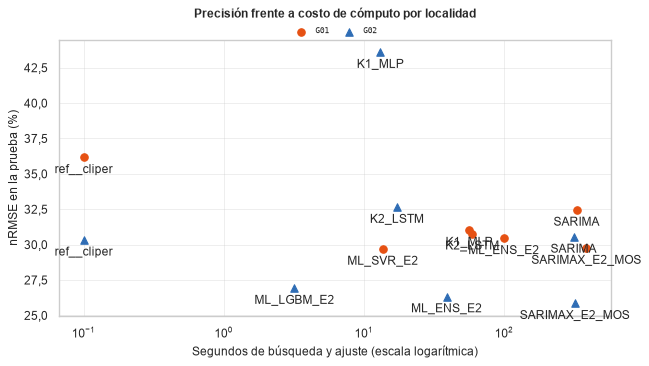

67 filas x 3 columnas; primeras 10:


nrmse_pct  seg_ajuste_final  seg_busqueda
localidad modelo                                                   
G01       ML_SVR_E2         29.6855             0.714        12.912
          SARIMAX_E2_MOS    29.7470           160.497       225.452
          ML_ENS_E2         30.4383             7.011        92.444
          K2_LSTM           30.7636            59.212           NaN
          K1_MLP            31.0213            56.236           NaN
          SARIMA            32.4430           102.935       225.452
          ref__cliper       36.1588               NaN           NaN
G03       ML_ENS_E2         34.9195             2.752        57.702
          K2_LSTM           35.0327            94.803           NaN
          SARIMAX_E2_MOS    35.0595           117.555       281.006

In [10]:
filas_f = []
for g, v in LOC.items():
    mf = v.get("modelo_final", {})
    if mf:
        multi = pd.DataFrame(mf.get("multicriterio", {})).T
        filas_f.append({"localidad": g, "modelo_recomendado": mf.get("modelo"), "mejor_en_prueba": mf.get("mejor_en_prueba"),
                        "empatados": ", ".join(mf.get("empatados", [])), "fuente_pronostico": mf.get("fuente_pronostico"),
                        "fuente_observada": mf.get("fuente_observada"),
                        "nrmse_recomendado": multi.loc[mf.get("modelo"), "nrmse_pct"] if mf.get("modelo") in multi.index else np.nan})
FINALES = pd.DataFrame(filas_f).set_index("localidad") if filas_f else pd.DataFrame()
display(FINALES)
COSTOS = {g: pd.DataFrame(v.get("modelo_final", {}).get("multicriterio", {})).T for g, v in LOC.items()}
COSTOS = {g: c for g, c in COSTOS.items() if not c.empty}
if COSTOS:
    cs = pd.concat({g: c[["nrmse_pct", "seg_ajuste_final", "seg_busqueda"]].astype(float) for g, c in COSTOS.items()}, names=["localidad", "modelo"])
    display(Markdown("**Precisión y costo por modelo** (segundos de ajuste final y de búsqueda de hiperparámetros)")); display(cs.round(2))
    f, ax = plt.subplots(figsize=(8, 4.5))
    COSTOS_G = {g: COSTOS[g] for g in ("G01", "G02") if g in COSTOS}        # figura: las dos localidades en detalle
    for (g, c), e in zip(COSTOS_G.items(), gr.estilos_series(len(COSTOS_G))):
        seg = c["seg_ajuste_final"].astype(float).fillna(0) + c["seg_busqueda"].astype(float).fillna(0)
        ax.scatter(seg.clip(lower=0.1), c["nrmse_pct"].astype(float), color=e["color"], marker=e["marker"], s=45, label=g)
        for k in c.index:
            ax.annotate(k, (max(seg[k], 0.1), float(c.loc[k, "nrmse_pct"])), fontsize=6, xytext=(0, -6), textcoords="offset points",
                        ha="center", va="top")
    ax.set_xscale("log"); ax.set_xlabel("Segundos de búsqueda y ajuste (escala logarítmica)"); ax.set_ylabel("nRMSE en la prueba (%)")
    ax.legend(); ax.set_title("Precisión frente a costo de cómputo por localidad")
    fig(f, "precision_costo", cs)

## 7. Síntesis

In [11]:
SINTESIS = {
    "localidades": list(LOC),
    "mejor_modelo_prueba": mejores,
    "nrmse_prueba_mejor": {g: float(prueba[g].loc[m, "nrmse_pct"]) for g, m in mejores.items()},
    "skill_prueba_mejor": {g: float(prueba[g].loc[m, "skill_vs_cliper"]) for g, m in mejores.items()},
    "fuente_irradiancia": DECISIONES["fuente_irradiancia"].to_dict(),
    "imputacion": DECISIONES["imputacion"].to_dict(),
    "modelo_recomendado": FINALES["modelo_recomendado"].to_dict() if len(FINALES) else {},
    "fuente_pronostico": FINALES["fuente_pronostico"].to_dict() if len(FINALES) else {},
}
# Clave por clave: registrar el nodo entero borraria lo que este cuaderno ya registro arriba (mapa de calor, cajas y
# total mensual)
for k_, v_ in SINTESIS.items():
    res.registrar(f"comparacion.{k_}", v_)
display(pd.DataFrame(SINTESIS["nrmse_prueba_mejor"], index=["nRMSE prueba"]).T.round(2))

,nRMSE prueba
G01,29.69
G03,34.92
G02,25.85
G04,25.40
G05,33.35
G06,41.08
G07,36.92
G09,17.62
G11,29.33
G13,38.33


## 8. Toda la flota: viabilidad y resultado por unidad

Cada grupo se ejecutó una vez para su unidad principal y una vez por cada otra unidad viable (inversores y
plantas de varios inversores). Esta tabla reúne la viabilidad de cada unidad, la partición que usó, el modelo
elegido con la regla de simplicidad y su error en la prueba frente a CLIPER. El ranking de modelos muestra,
para cada modelo, el error en la prueba de todas las unidades en que se evaluó y la distribución de su skill.

In [12]:
import re
clave = lambda s: re.sub(r"[^A-Za-z0-9_]", "_", str(s))
filas, errores = [], []
for g, v in sorted(R.get("localidades", {}).items()):
    um = v.get("unidades_modelables", {})
    for u, info in um.get("unidades", {}).items():
        fila = {"grupo": g, "unidad": u, "tipo": info.get("tipo"), "principal": u == um.get("principal"),
                "modelable": info.get("modelable"), "particion": info.get("particion"),
                "dias_entrenamiento": info.get("dias_entrenamiento"), "ml_indicativo": info.get("ml_bajo_minimo")}
        pr = v.get("modelos", {}).get(f"prueba_h2_{u}", {})
        mf = v.get("unidades", {}).get(u, {}).get("modelo_final", {}) or (v.get("modelo_final", {}) if u == um.get("principal") else {})
        if pr:
            elegido = mf.get("modelo")
            e = pr.get(clave(elegido), {}) if elegido else {}
            mejor = min((k for k in pr if not k.startswith("ref")), key=lambda k: pr[k].get("nrmse_pct", np.inf), default=None)
            fila.update({"modelo_elegido": elegido, "nrmse_elegido": e.get("nrmse_pct"), "skill_elegido": e.get("skill_vs_cliper"),
                         "mejor_en_prueba": mejor, "nrmse_mejor": pr.get(mejor, {}).get("nrmse_pct") if mejor else None,
                         "nrmse_cliper": pr.get("ref__cliper", {}).get("nrmse_pct"),
                         "nrmse_persistencia_estacional": pr.get("ref__persistencia", {}).get("nrmse_pct")})
            for k, m in pr.items():
                errores.append({"grupo": g, "unidad": u, "modelo": k, "nrmse_pct": m.get("nrmse_pct"), "skill": m.get("skill_vs_cliper")})
        filas.append(fila)
FLOTA = pd.DataFrame(filas).set_index("unidad") if filas else pd.DataFrame()
display(FLOTA)
ERRORES = pd.DataFrame(errores)
res.registrar("comparacion.flota", FLOTA.to_dict(orient="index"))
if not FLOTA.empty:
    resumen = {"unidades": int(len(FLOTA)), "modelables": int(FLOTA["modelable"].fillna(False).sum()),
               "particion_propia": int((FLOTA["particion"] == "propia").sum()),
               "ml_indicativo": int((FLOTA["ml_indicativo"].fillna(False) & FLOTA["modelable"].fillna(False)).sum()),
               "solo_exploracion": FLOTA.index[~FLOTA["modelable"].fillna(False)].tolist()}
    if "modelo_elegido" in FLOTA:
        resumen["modelo_elegido_conteo"] = FLOTA["modelo_elegido"].value_counts().to_dict()
        resumen["skill_elegido_mediana"] = float(FLOTA["skill_elegido"].median())
        resumen["nrmse_elegido_mediana"] = float(FLOTA["nrmse_elegido"].median())
    res.registrar("comparacion.flota_resumen", resumen)
    display(pd.Series(resumen, dtype=object).to_frame("valor"))

,grupo,tipo,principal,modelable,particion,dias_entrenamiento,ml_indicativo,modelo_elegido,nrmse_elegido,skill_elegido,mejor_en_prueba,nrmse_mejor,nrmse_cliper,nrmse_persistencia_estacional
unidad,,,,,,,,,,,,,,
P01I0102,G01,inversor,True,True,fija,380,False,SARIMAX E2-MOS,29.7470,0.17732,ML_SVR_E2,29.6855,36.1588,43.2026
P01I0202,G01,inversor,False,True,fija,378,False,SARIMAX E2-MOS,29.7869,0.17513,ML_ENS_E2,29.5732,36.1110,43.7892
P07I0101,G01,inversor,False,True,fija,114,False,SARIMAX E2-MOS,29.2003,0.19670,K2_LSTM,29.1331,36.3504,41.2645
P01,G01,planta,False,True,fija,374,False,SARIMAX E2-MOS,29.1115,0.17685,SARIMAX_E2_MOS,29.1115,35.3659,42.6083
P04I0102,G02,inversor,False,True,propia,130,False,ref: cliper,31.9253,0.00000,ML_ENS_E2,25.7667,31.9253,35.9521
P04I0202,G02,inversor,True,True,propia,134,False,ref: cliper,30.3306,0.00000,SARIMAX_E2_MOS,25.8494,30.3306,36.2866
P04,G02,planta,False,True,propia,130,False,ref: cliper,30.7690,0.00000,SARIMAX_E2_MOS,25.0056,30.7690,35.7728
P02I0102,G03,inversor,False,True,fija,277,False,ML LGBM E2,36.3615,0.12650,ML_ENS_E2,36.1671,41.6275,51.5164
P02I0202,G03,inversor,True,True,fija,279,False,SARIMAX E2-MOS,35.0595,0.15496,ML_ENS_E2,34.9195,41.4885,49.1790


,valor
unidades,30
modelables,28
particion_propia,16
ml_indicativo,15
solo_exploracion,"[P17I0101, P18I0101]"
modelo_elegido_conteo,"{'ref: cliper': 15, 'SARIMAX E2-MOS': 9, 'SARI..."
skill_elegido_mediana,0.0
nrmse_elegido_mediana,36.0637


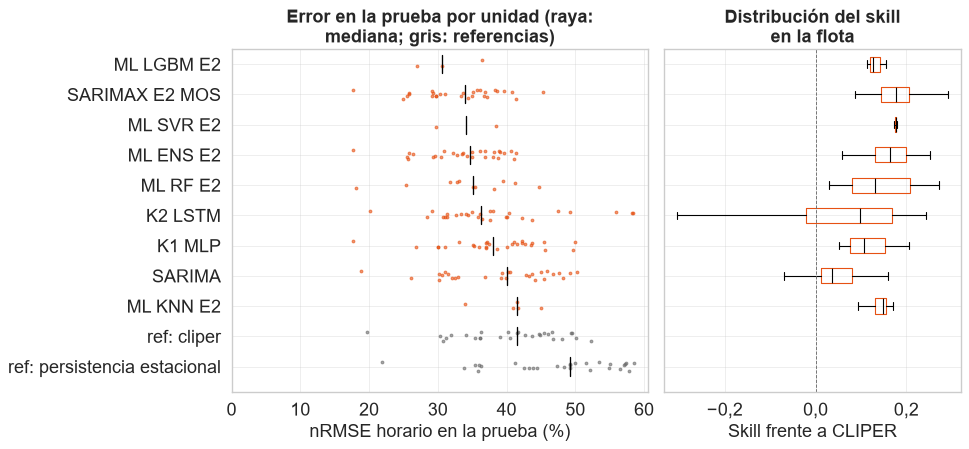

217 filas x 5 columnas; primeras 10:


,grupo,unidad,modelo,nrmse_pct,skill
0,G01,P01I0102,ML SVR E2,29.6855,0.1790
1,G01,P01I0102,SARIMAX E2 MOS,29.7470,0.1773
2,G01,P01I0102,ML ENS E2,30.4383,0.1582
3,G01,P01I0102,K2 LSTM,30.7636,0.1492
4,G01,P01I0102,K1 MLP,31.0213,0.1421
5,G01,P01I0102,SARIMA,32.4430,0.1028
6,G01,P01I0102,ref: cliper,36.1588,0.0000
7,G01,P01I0102,ref: persistencia estacional,43.2026,-0.1948
8,G01,P01I0202,ML ENS E2,29.5732,0.1810
9,G01,P01I0202,SARIMAX E2 MOS,29.7869,0.1751


,unidades,nrmse_mediana,skill_mediana
modelo,,,
ML LGBM E2,3,30.671,0.126
SARIMAX E2 MOS,28,34.018,0.177
ML SVR E2,2,34.109,0.176
ML ENS E2,28,34.614,0.165
ML RF E2,11,35.086,0.131
K2 LSTM,28,36.259,0.097
K1 MLP,28,38.020,0.108
SARIMA,28,40.065,0.037
ML KNN E2,5,41.511,0.149


In [13]:
if not ERRORES.empty:
    E = ERRORES.dropna(subset=["nrmse_pct"]).copy()
    E["modelo"] = E["modelo"].str.replace("ref__", "ref: ", regex=False).str.replace("_", " ")
    E["modelo"] = E["modelo"].replace({"ref: persistencia": "ref: persistencia estacional"})
    orden = E.groupby("modelo")["nrmse_pct"].median().sort_values().index.tolist()
    f, ax = plt.subplots(1, 2, figsize=(12, 0.34 * len(orden) + 1.8), sharey=True, gridspec_kw={"width_ratios": [1.4, 1]})
    for i, m in enumerate(orden):
        s = E.loc[E["modelo"] == m, "nrmse_pct"]
        ref = m.startswith("ref")
        color = config.COLOR_NEUTRO if ref else config.COLOR_PRINCIPAL
        ax[0].scatter(s, np.full(len(s), i) + np.random.default_rng(37).uniform(-0.15, 0.15, len(s)), s=6, color=color, alpha=0.6)
        ax[0].plot([s.median()] * 2, [i - 0.3, i + 0.3], color="black", ls="-", lw=1.2)
        k = E.loc[(E["modelo"] == m), "skill"].dropna()
        if len(k) and not ref:
            ax[1].boxplot(k, positions=[i], orientation="horizontal", widths=0.5, showfliers=False,
                          medianprops={"color": "black"}, boxprops={"color": config.COLOR_PRINCIPAL})
    ax[0].set_yticks(range(len(orden)), orden, fontsize=7); ax[0].invert_yaxis()
    ax[0].set_xlabel("nRMSE horario en la prueba (%)"); ax[0].set_xlim(left=0)
    ax[0].set_title("Error en la prueba por unidad (raya: mediana; gris: referencias)")
    ax[1].axvline(0, color=config.COLOR_NEUTRO, lw=0.8, ls="--")
    ax[1].set_xlabel("Skill frente a CLIPER"); ax[1].set_title("Distribución del skill en la flota")
    fig(f, "ranking_modelos", E)
    RANKING = E.groupby("modelo").agg(unidades=("unidad", "nunique"), nrmse_mediana=("nrmse_pct", "median"),
                                      skill_mediana=("skill", "median")).sort_values("nrmse_mediana")
    display(RANKING.round(3))
    res.registrar("comparacion.ranking", RANKING.round(4).to_dict(orient="index"))

### 8.1 Auditoría de los datos de la flota

Dos resultados de los cuadernos por grupo condicionan la lectura de toda la flota: el **nivel de cada fuente de
irradiancia** frente a NSRDB (con el que se calibran las fuentes observadas) y la **auditoría de la potencia
pico** de cada inversor (prueba física con el percentil 99 de la potencia DC e identificación en horas
despejadas). Aquí se reúnen.

### 8.2 Capacidad efectiva y error del pronóstico

Si la producción de una unidad depende de algo que no es el tiempo meteorológico, el pronóstico desde la
meteorología pierde precisión. En el régimen vigente las horas recortadas por la limitación de inyección ya están
fuera (cuaderno de calidad de la flota), así que esta clase solo debería reunir unidades con cadenas desconectadas o
un $P_0$ sobreestimado; si aparece una unidad limitada, es una señal de recorte que la regla no detectó. La clasificación no se hace con un
umbral absoluto de $PR$, que dependería de la fuente y del $P_0$ declarado, sino con la auditoría de la potencia
pico: se comparan las unidades de capacidad efectiva limitada (sus picos de potencia no pasan del 70 % del $P_0$ y
la identificación lo confirma) con las demás, con la prueba de Mann-Whitney. La correlación de Spearman entre el
$PR$ mediano (ya al nivel de NSRDB y con el $P_0$ que fija la auditoría) y el error se informa como complemento.

In [14]:
filas_n, filas_p = [], []
for g, v in sorted(R.get("localidades", {}).items()):
    for fuente, d in v.get("datos", {}).get("nivel_fuentes", {}).items():
        filas_n.append({"grupo": g, "fuente": fuente, **d})
    for u, d in v.get("datos", {}).get("auditoria_p0", {}).items():
        filas_p.append({"grupo": g, "inversor": u, **d})
NIVEL_FLOTA = pd.DataFrame(filas_n)
P0_FLOTA = pd.DataFrame(filas_p).set_index("inversor") if filas_p else pd.DataFrame()
if not NIVEL_FLOTA.empty:
    FACT = NIVEL_FLOTA.pivot_table(index="grupo", columns="fuente", values="factor")
    display(Markdown("**Factor de nivel de cada fuente frente a NSRDB por grupo** (irradiación de NSRDB / de la fuente, 2025)"))
    display(FACT.round(3))
    display(FACT.describe().loc[["min", "50%", "max"]].round(3))
    res.registrar("comparacion.nivel_fuentes", {"mediana": FACT.median().round(4).to_dict(), "minimo": FACT.min().round(4).to_dict(),
                  "maximo": FACT.max().round(4).to_dict()})
if not P0_FLOTA.empty:
    display(Markdown("**Auditoría de la potencia pico por inversor**"))
    cols_p0 = [c for c in ("grupo", "kwp_declarado", "p99_dc_kw", "p99_dc_sobre_kwp", "kwp_identificado", "r", "kwp_analisis", "decision")
               if c in P0_FLOTA]
    display(P0_FLOTA[cols_p0].round(3))
    conteo_p0 = P0_FLOTA["decision"].value_counts()
    display(conteo_p0.to_frame("inversores"))
    # Con el kWp del instalador, la identificación es un control: su cociente con el declarado mide lo que el modelo de
    # identificación no recoge (suciedad, desajuste, cableado y el nivel de la irradiancia)
    R_P0 = pd.to_numeric(P0_FLOTA["r"], errors="coerce").dropna() if "r" in P0_FLOTA else pd.Series(dtype=float)
    REVISAR_P0 = P0_FLOTA.index[P0_FLOTA["decision"].str.contains("imposible|subestimado")].tolist()
    if len(R_P0):
        display(Markdown(
            f"En los {len(R_P0)} inversores con horas despejadas suficientes, el kWp identificado es en la mediana "
            f"{R_P0.median():.2f} veces el declarado (de {R_P0.min():.2f} a {R_P0.max():.2f}). Como la potencia pico la confirmó "
            "el instalador, la diferencia reúne lo que el modelo de identificación no recoge: suciedad, desajuste entre "
            "módulos, pérdidas de cableado y el nivel de la irradiancia. "
            + (f"La telemetría entrega más de lo que permite el kWp declarado en {', '.join(REVISAR_P0)}: es un dato por revisar."
               if REVISAR_P0 else "En ninguna unidad la telemetría entrega más de lo que permite el kWp declarado.")))
    res.registrar("comparacion.auditoria_p0", {"conteo": conteo_p0.to_dict(), "inversores": int(len(P0_FLOTA)),
                  "r_mediana": round(float(R_P0.median()), 4) if len(R_P0) else None,
                  "r_minimo": round(float(R_P0.min()), 4) if len(R_P0) else None,
                  "r_maximo": round(float(R_P0.max()), 4) if len(R_P0) else None,
                  "r_inversores": int(len(R_P0)), "n_por_revisar": len(REVISAR_P0), "por_revisar": REVISAR_P0,
                  "n_corregidos": int(P0_FLOTA["decision"].str.startswith("identificado").sum()),
                  "n_limitados": int(P0_FLOTA["decision"].str.contains("limitada").sum()),
                  "n_no_concluyentes": int(P0_FLOTA["decision"].str.contains("no concluyente").sum()),
                  "corregidos": P0_FLOTA.index[P0_FLOTA["decision"].str.startswith("identificado")].tolist(),
                  "limitados": P0_FLOTA.index[P0_FLOTA["decision"].str.contains("limitada")].tolist(),
                  "no_concluyentes": P0_FLOTA.index[P0_FLOTA["decision"].str.contains("no concluyente")].tolist()})
# Horas sin producción con sol y sin estado de falla dentro del régimen vigente (excluidas como la falla en cada cuaderno)
filas_sp = [{"grupo": g, "unidad": u, **d} for g, v in sorted(R.get("localidades", {}).items())
            for u, d in v.get("datos", {}).get("sin_produccion", {}).items() if isinstance(d, dict)]
SP_FLOTA = pd.DataFrame(filas_sp).set_index("unidad") if filas_sp else pd.DataFrame()
if not SP_FLOTA.empty:
    con_sp = SP_FLOTA[SP_FLOTA["horas"] > 0].sort_values("horas", ascending=False)
    display(Markdown(f"**Horas sin producción con sol, sin estado de falla, en el régimen vigente** ({len(con_sp)} de {len(SP_FLOTA)} "
                     f"inversores con alguna; {int(SP_FLOTA['horas'].sum())} horas en {int(SP_FLOTA['dias'].sum())} días-inversor)"))
    display(con_sp)
    res.registrar("comparacion.sin_produccion", {"inversores": int(len(SP_FLOTA)), "inversores_con_horas": int(len(con_sp)),
                  "horas": int(SP_FLOTA["horas"].sum()), "dias": int(SP_FLOTA["dias"].sum()),
                  "por_unidad": con_sp.drop(columns="grupo").to_dict(orient="index")})

**Factor de nivel de cada fuente frente a NSRDB por grupo** (irradiación de NSRDB / de la fuente, 2025)

fuente,era5,gfs_pronostico_d1,ifs025_pronostico_d1,ifs_analisis,nasa_power,nsrdb_goes,satelite_msg
grupo,,,,,,,
G01,1.112,1.070,1.028,0.997,1.006,1.0,0.887
G02,1.052,1.104,1.014,1.010,1.045,1.0,0.858
G03,1.024,1.070,1.049,1.010,1.080,1.0,0.950
G04,1.048,1.085,1.074,1.030,1.018,1.0,0.949
G05,1.009,1.074,1.063,1.020,1.008,1.0,0.972
G06,1.039,1.042,1.057,1.035,1.046,1.0,NaN
G07,1.078,1.057,1.045,1.040,1.066,1.0,NaN
G08,1.067,1.030,1.042,1.058,1.080,1.0,NaN
G09,1.078,1.037,1.116,1.060,1.120,1.0,0.877


fuente,era5,gfs_pronostico_d1,ifs025_pronostico_d1,ifs_analisis,nasa_power,nsrdb_goes,satelite_msg
min,1.005,0.888,0.894,0.941,1.006,1.0,0.858
50%,1.050,1.070,1.053,1.028,1.045,1.0,0.943
max,1.112,1.112,1.116,1.060,1.230,1.0,0.972


**Auditoría de la potencia pico por inversor**

,grupo,kwp_declarado,p99_dc_kw,p99_dc_sobre_kwp,kwp_identificado,r,kwp_analisis,decision
inversor,,,,,,,,
P01I0102,G01,36.850,28.960,0.786,32.832,0.891,36.850,instalador; telemetria: coherente con la telem...
P01I0202,G01,14.070,11.833,0.841,12.052,0.857,14.070,instalador; telemetria: coherente con la telem...
P07I0101,G01,73.130,58.615,0.802,65.553,0.896,73.130,instalador; telemetria: coherente con la telem...
P04I0102,G02,44.800,42.883,0.957,41.516,0.927,44.800,instalador; telemetria: coherente con la telem...
P04I0202,G02,53.200,44.544,0.837,43.970,0.826,53.200,instalador; telemetria: coherente con la telem...
P02I0102,G03,6.765,4.222,0.624,4.298,0.635,6.765,instalador; telemetria: capacidad efectiva lim...
P02I0202,G03,13.530,8.597,0.635,8.927,0.660,13.530,instalador; telemetria: capacidad efectiva lim...
P03I0103,G03,65.100,49.794,0.765,49.579,0.762,65.100,instalador; telemetria: coherente con la telem...
P03I0203,G03,65.100,52.616,0.808,54.963,0.844,65.100,instalador; telemetria: coherente con la telem...


,inversores
decision,
instalador; telemetria: coherente con la telemetria,20
instalador; telemetria: sin horas despejadas suficientes,15
instalador; telemetria: capacidad efectiva limitada,2


En los 22 inversores con horas despejadas suficientes, el kWp identificado es en la mediana 0,85 veces el declarado (de 0,64 a 1,08). Como la potencia pico la confirmó el instalador, la diferencia reúne lo que el modelo de identificación no recoge: suciedad, desajuste entre módulos, pérdidas de cableado y el nivel de la irradiancia. En ninguna unidad la telemetría entrega más de lo que permite el kWp declarado.

**Horas sin producción con sol, sin estado de falla, en el régimen vigente** (19 de 24 inversores con alguna; 472 horas en 110 días-inversor)

,grupo,horas,dias,ultimo_dia
unidad,,,,
P08I0101,G04,287,37,2026-10-31
P19I0102,G03,47,9,2026-10-24
P19I0202,G03,45,7,2026-10-24
P05I0101,G06,21,6,2026-10-24
P09I0101,G09,14,6,2026-04-07
P02I0102,G03,10,8,2026-10-24
P02I0202,G03,9,7,2026-10-24
P15I0101,G13,8,6,2026-10-24
P10I0101,G07,7,4,2026-10-24


**Error del modelo elegido según la capacidad efectiva.** Capacidad limitada: 2 inversores, nRMSE mediano 35,7 %; resto: 20, 37,8 % (Mann-Whitney, p = nan).

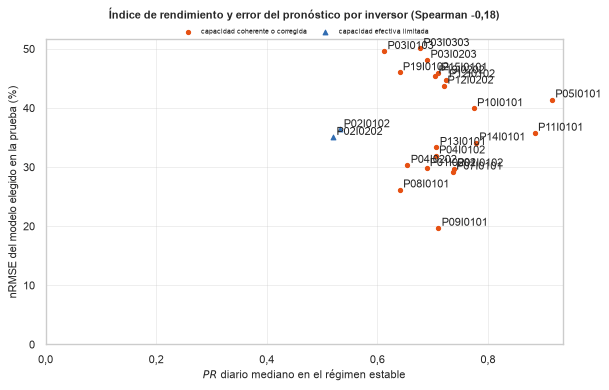

22 filas x 4 columnas; primeras 10:


,grupo,pr_mediano,nrmse_elegido,modelo_elegido
unidad,,,,
P01I0102,G01,0.7383,29.7470,SARIMAX E2-MOS
P01I0202,G01,0.6889,29.7869,SARIMAX E2-MOS
P07I0101,G01,0.7367,29.2003,SARIMAX E2-MOS
P04I0102,G02,0.7056,31.9253,ref: cliper
P04I0202,G02,0.6544,30.3306,ref: cliper
P02I0102,G03,0.5332,36.3615,ML LGBM E2
P02I0202,G03,0.5201,35.0595,SARIMAX E2-MOS
P03I0103,G03,0.6124,49.5891,ref: cliper
P03I0203,G03,0.6901,48.0981,ref: cliper


In [15]:
from scipy.stats import mannwhitneyu
if not FLOTA.empty and "nrmse_elegido" in FLOTA:
    clase = {u: ("capacidad limitada" if "limitada" in str(P0_FLOTA.loc[u, "decision"]) else "resto")
             for u in FLOTA.index if not P0_FLOTA.empty and u in P0_FLOTA.index}
    CAP = FLOTA.assign(clase=pd.Series(clase)).dropna(subset=["clase", "nrmse_elegido"])
    a_, b_ = CAP.loc[CAP["clase"] == "capacidad limitada", "nrmse_elegido"], CAP.loc[CAP["clase"] == "resto", "nrmse_elegido"]
    p_mw = float(mannwhitneyu(a_, b_).pvalue) if len(a_) >= 3 and len(b_) >= 3 else np.nan
    display(Markdown(f"**Error del modelo elegido según la capacidad efectiva.** Capacidad limitada: {len(a_)} inversores, nRMSE "
                     f"mediano {a_.median():.1f} %; resto: {len(b_)}, {b_.median():.1f} % (Mann-Whitney, p = {p_mw:.3g})."))
    res.registrar("comparacion.capacidad_vs_error", {"limitada": a_.index.tolist(), "nrmse_mediano_limitada": float(a_.median()) if len(a_) else None,
                  "nrmse_mediano_resto": float(b_.median()) if len(b_) else None, "p_mann_whitney": p_mw})
    pr_med = {u: R["localidades"][g].get("objetivos", {}).get(u, {}).get("pr_mediano") for u, g in FLOTA["grupo"].items()}
    PRE = FLOTA.assign(pr_mediano=pd.Series(pr_med)).dropna(subset=["pr_mediano", "nrmse_elegido"])
    PRE = PRE[PRE["tipo"] == "inversor"]
    rho = PRE["pr_mediano"].corr(PRE["nrmse_elegido"], method="spearman")
    f, ax = plt.subplots(figsize=(7.5, 4.8))
    lim_ = PRE.index.isin(CAP.index[CAP["clase"] == "capacidad limitada"])
    ax.scatter(PRE.loc[~lim_, "pr_mediano"], PRE.loc[~lim_, "nrmse_elegido"], s=14, color=config.COLOR_PRINCIPAL, zorder=3,
               label="capacidad coherente o corregida")
    ax.scatter(PRE.loc[lim_, "pr_mediano"], PRE.loc[lim_, "nrmse_elegido"], s=18, marker="^", color=config.COLOR_SECUNDARIO, zorder=3,
               label="capacidad efectiva limitada")
    ax.legend(fontsize=8)
    for u, r in PRE.iterrows():
        ax.annotate(u, (r["pr_mediano"], r["nrmse_elegido"]), fontsize=6, xytext=(3, 2), textcoords="offset points")
    ax.set_xlabel("PR diario mediano en el régimen estable"); ax.set_ylabel("nRMSE del modelo elegido en la prueba (%)")
    ax.set_xlim(left=0); ax.set_ylim(bottom=0)
    ax.set_title(f"Índice de rendimiento y error del pronóstico por inversor (Spearman {rho:.2f})")
    fig(f, "pr_vs_error", PRE[["grupo", "pr_mediano", "nrmse_elegido", "modelo_elegido"]])
    res.registrar("comparacion.pr_vs_error", {"spearman": float(rho), "inversores": int(len(PRE)),
                  "pr_bajo_06": PRE.index[PRE["pr_mediano"] < 0.6].tolist(),
                  "nrmse_mediano_pr_bajo": float(PRE.loc[PRE["pr_mediano"] < 0.6, "nrmse_elegido"].median()),
                  "nrmse_mediano_pr_normal": float(PRE.loc[PRE["pr_mediano"] >= 0.6, "nrmse_elegido"].median())})

## 9. Suficiencia de datos de la flota y regla para una planta nueva

Cada cuaderno por unidad repitió el experimento de suficiencia del SARIMAX E2-MOS desde cuatro orígenes de su régimen
vigente (sección L.2), y aquí juntamos las curvas. Para que las unidades sean comparables, expresamos el error de cada
una relativo al que alcanza con toda la historia del régimen en las mismas horas (su asíntota), origen por origen, y lo
resumimos con la mediana de los orígenes. Lo que se puede generalizar es el **número de días hasta la asíntota**,
porque el nivel de la asíntota depende de cada lugar (la variabilidad de las nubes y la calidad del pronóstico
meteorológico). Un ajuste explosivo o fallido cuenta como error infinito, ya que con esos días no hay un modelo útil.

En el día 0 una planta nueva solo tiene el modelo global entrenado sin ella (validación agrupada por planta). Medimos su
error en la prueba y lo dividimos por el del SARIMAX E2-MOS de la misma unidad en las mismas horas, entrenado con toda
la historia del régimen.

Definimos $d^*$ como el menor número de días desde el cual la mediana de la flota queda a menos de un 5 % de la
asíntota y así sigue con más días (usamos $d$ y no $k$ para no confundirlo con el índice de cielo despejado $k^*$), y
lo acompañamos de una prueba de no inferioridad con ese margen, que es un Wilcoxon de rangos con signo sobre el
logaritmo del error relativo menos el logaritmo de 1,05, con la hipótesis alternativa de que la mediana queda por
debajo. De ahí sale la regla, según la cual una planta nueva, una ampliación o una planta que deja de limitar la
inyección se pronostica con el modelo global hasta acumular $d^*$ días limpios del régimen nuevo, y desde entonces con
su SARIMAX E2-MOS.

**Error relativo a la asíntota por días de entrenamiento** (27 unidades; mediana de los orígenes de cada unidad y, entre unidades, mediana y cuartiles)

,mediana_relativa,p25,p75,unidades,sin_modelo_util,p_no_inferioridad
3,1.404,1.131,1.750,27,1,1.000
7,1.115,1.056,1.690,27,0,1.000
14,1.025,0.994,1.086,27,0,0.314
21,1.029,1.009,1.141,27,0,0.826
30,1.012,1.003,1.060,27,0,0.071
60,0.997,0.986,1.004,17,0,0.000


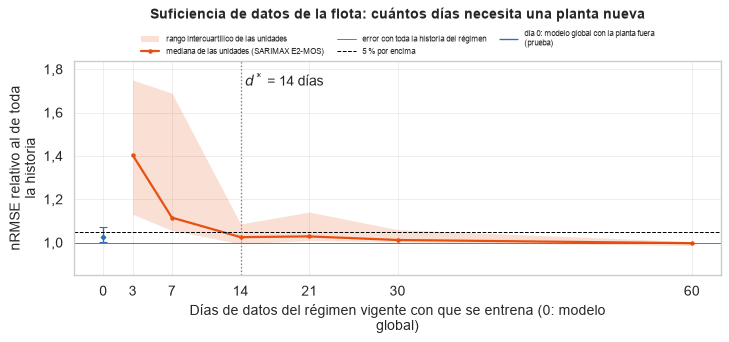

6 filas x 6 columnas; primeras 6:


,mediana_relativa,p25,p75,unidades,sin_modelo_util,p_no_inferioridad
3,1.4037,1.1310,1.7504,27,1,1.0000
7,1.1153,1.0557,1.6900,27,0,0.9999
14,1.0251,0.9942,1.0862,27,0,0.3138
21,1.0286,1.0093,1.1409,27,0,0.8258
30,1.0120,1.0030,1.0598,27,0,0.0707
60,0.9972,0.9862,1.0043,17,0,0.0000


Con 27 unidades, desde **14 días** de datos la mediana de la flota queda a menos de un 5 % del error con toda la historia del régimen, y así sigue con más días (no inferioridad con ese margen: p = 0,314). Con menos días, el modelo de la unidad no sirve en algunas: 1 de 27 con 3 días. El día 0, el modelo global con la planta fuera del entrenamiento da en la prueba un error 3 % mayor que el SARIMAX E2-MOS de la unidad en las mismas horas (mediana de 13 unidades). La regla operativa es: modelo global hasta acumular $d^*$ días limpios del régimen nuevo; después, el SARIMAX E2-MOS de la unidad.

In [16]:
from scipy.stats import wilcoxon
FALLAS_SUF = ("ajuste explosivo", "ajuste fallido")
TOPE_REL = 10.0          # un error infinito (sin modelo útil) se acota solo para los cuantiles, la prueba y la figura
curvas, por_unidad = {}, {}
for g, v in LOC.items():
    for clave, val in v.get("modelos", {}).items():
        if not (clave.startswith("suficiencia_origenes_") and isinstance(val, dict) and "motivos" in val):
            continue
        e = pd.DataFrame(val.get("nrmse_pct", {})).T.apply(pd.to_numeric, errors="coerce")   # filas: días (y todo); columnas: origen
        if "todo" not in e.index or e.loc["todo"].notna().sum() == 0:
            continue
        u = clave.replace("suficiencia_origenes_", "")
        mot = pd.DataFrame(val.get("motivos", {})).T.reindex(index=e.index, columns=e.columns)
        ref = e.loc["todo"]
        rel = e.drop(index="todo") / ref
        rel = rel.mask(mot.drop(index="todo").isin(FALLAS_SUF) & ref.notna(), np.inf)
        rel.index = rel.index.astype(int)
        curvas[u] = rel.median(axis=1, skipna=True)
        por_unidad[u] = {"grupo": g, "origenes": int(ref.notna().sum()), "d_minimo_5pct": val.get("d_minimo_5pct"),
                         "nrmse_todo_mediano_pct": val.get("nrmse_todo_mediano_pct")}
REL_U = pd.DataFrame(curvas).sort_index()
if REL_U.empty:
    display(Markdown("Sin curvas de suficiencia desde varios orígenes todavía (las escriben los cuadernos por unidad)."))
else:
    REL_T = REL_U.replace(np.inf, TOPE_REL)
    def p_no_inferior(fila):
        x = np.log(fila.dropna()) - np.log(1.05)
        x = x[x != 0]
        return float(wilcoxon(x, alternative="less").pvalue) if len(x) >= 6 else np.nan
    RES_SUF = pd.DataFrame({"mediana_relativa": REL_U.median(axis=1), "p25": REL_T.quantile(0.25, axis=1),
                            "p75": REL_T.quantile(0.75, axis=1), "unidades": REL_U.notna().sum(axis=1),
                            "sin_modelo_util": np.isinf(REL_U).sum(axis=1),
                            "p_no_inferioridad": [p_no_inferior(REL_T.loc[d]) for d in REL_T.index]})
    ok_d = RES_SUF["mediana_relativa"] <= 1.05
    D_ESTRELLA = next((int(d) for i, d in enumerate(ok_d.index) if ok_d.iloc[i:].all()), None)
    cj = R.get("global", {}).get("cajas_flota", {}).get("por_unidad", {})
    dia0 = pd.Series({u: r["global_planta_nueva"] / r["sarimax_individual"] for u, r in cj.items()
                      if r.get("global_planta_nueva") and r.get("sarimax_individual")}, dtype=float)
    display(Markdown(f"**Error relativo a la asíntota por días de entrenamiento** ({REL_U.shape[1]} unidades; mediana de los orígenes de cada "
                     "unidad y, entre unidades, mediana y cuartiles)"))
    display(RES_SUF.round(3))
    f, ax = plt.subplots(figsize=(9, 4.2))
    x = RES_SUF.index.to_numpy()
    ax.fill_between(x, RES_SUF["p25"], RES_SUF["p75"], color=config.COLOR_PRINCIPAL, alpha=0.18, lw=0,
                    label="rango intercuartílico de las unidades")
    ax.plot(x, RES_SUF["mediana_relativa"].clip(upper=TOPE_REL), color=config.COLOR_PRINCIPAL, ls="-", marker="o", lw=2,
            label="mediana de las unidades (SARIMAX E2-MOS)")
    if len(dia0):
        ax.errorbar([0], [dia0.median()], yerr=[[dia0.median() - dia0.quantile(0.25)], [dia0.quantile(0.75) - dia0.median()]],
                    fmt="D", color=config.COLOR_SECUNDARIO, capsize=4, label="día 0: modelo global con la planta fuera (prueba)")
    ax.axhline(1.0, color=config.COLOR_NEUTRO, lw=0.8, label="error con toda la historia del régimen")
    ax.axhline(1.05, color="black", ls="--", lw=0.9, label="5 % por encima")
    tope_y = float(np.clip(max(1.5, RES_SUF["p75"].max() * 1.05, dia0.quantile(0.75) * 1.05 if len(dia0) else 0), 1.5, 2.5))
    ax.set_ylim(0.85, tope_y)
    for d, r in RES_SUF.iterrows():
        if r["p75"] > tope_y:
            ax.annotate("cuartil superior\nfuera de escala", (d, tope_y), xytext=(0, -4), textcoords="offset points",
                        fontsize=7, ha="center", va="top", color=config.COLOR_NEUTRO)
    if D_ESTRELLA:
        ax.axvline(D_ESTRELLA, color="#7F7F7F", ls=":", lw=1.2)
        ax.annotate(f"$d^*$ = {D_ESTRELLA} días", (D_ESTRELLA, tope_y * 0.97), xytext=(4, 0), textcoords="offset points",
                    fontsize=9, ha="left", va="top")
    ax.set_xticks([0] + [int(d) for d in x])
    ax.set_xlabel("Días de datos del régimen vigente con que se entrena (0: modelo global)")
    ax.set_ylabel("nRMSE relativo al de toda la historia")
    ax.set_title("Suficiencia de datos de la flota: cuántos días necesita una planta nueva")
    ax.legend(fontsize=8, loc="upper right")
    fig(f, "suficiencia_flota", RES_SUF)
    p_d = RES_SUF["p_no_inferioridad"].get(D_ESTRELLA) if D_ESTRELLA else np.nan
    display(Markdown(
        f"Con {REL_U.shape[1]} unidades, "
        + (f"desde **{D_ESTRELLA} días** de datos la mediana de la flota queda a menos de un 5 % del error con toda la historia del régimen, "
           f"y así sigue con más días (no inferioridad con ese margen: p = {p_d:.3f}). " if D_ESTRELLA else
           "ninguna ventana corta deja la mediana de la flota de forma estable a menos de un 5 % del error con toda la historia. ")
        + (f"Con menos días, el modelo de la unidad no sirve en algunas: {', '.join(f'{int(r.sin_modelo_util)} de {int(r.unidades)} con {d} días' for d, r in RES_SUF.iterrows() if r.sin_modelo_util > 0)}. "
           if RES_SUF["sin_modelo_util"].sum() else "")
        + (f"El día 0, el modelo global con la planta fuera del entrenamiento da en la prueba un error {100 * (dia0.median() - 1):.0f} % mayor que "
           f"el SARIMAX E2-MOS de la unidad en las mismas horas (mediana de {len(dia0)} unidades). " if len(dia0) else "")
        + "La regla operativa es: modelo global hasta acumular $d^*$ días limpios del régimen nuevo; después, el SARIMAX E2-MOS de la unidad."))
    res.registrar("comparacion.suficiencia_flota", {"d_estrella": D_ESTRELLA, "unidades": int(REL_U.shape[1]),
                  "p_no_inferioridad_d_estrella": p_d, "curva": RES_SUF.round(4).to_dict(orient="index"),
                  "por_unidad": {u: {**por_unidad[u], "relativo": {int(d): (None if not np.isfinite(v) else round(float(v), 4))
                                                                    for d, v in REL_U[u].items()}} for u in REL_U.columns},
                  "dia0_global_relativo": {"mediana": float(dia0.median()) if len(dia0) else None,
                                           "p25": float(dia0.quantile(0.25)) if len(dia0) else None,
                                           "p75": float(dia0.quantile(0.75)) if len(dia0) else None, "unidades": int(len(dia0))}})

## 10. Degradación: qué permite medir la historia disponible

Los módulos pierden de 0,5 a 0,8 % de su rendimiento por año (marco teórico, degradación a largo plazo). Para medir esa
tasa en una unidad hay que separarla de dos variaciones mucho mayores, la del recurso solar de un año a otro, que el
índice de rendimiento ($PR$) descuenta pero el rendimiento específico ($Y_f$) no, y el ruido del $PR$ mensual (nubes
mal representadas por la irradiancia de satélite, suciedad, fallas cortas y el ciclo estacional de la temperatura). En
esta sección medimos las dos.

Para el recurso usamos la irradiación global horizontal anual de ERA5 de 2015 a 2024 en el punto de cada localidad
(años con al menos el 99 % de las horas) y calculamos el coeficiente de variación entre años y la mayor desviación de
un año respecto de la media. Son cocientes, así que no dependen del nivel de la fuente. Para el $PR$ tomamos el $PR$
diario del régimen vigente de cada inversor (días válidos) y calculamos el $PR$ mensual como cociente de sumas en los
meses con al menos 20 días, su desviación estándar relativa $\sigma_m$ y la recta ajustada a esos meses, con su
pendiente, su error estándar y la pendiente mínima detectable al 95 % (1,96 veces el error estándar). Con meses a
intervalos regulares durante $T$ años, ese error estándar es aproximadamente $\sigma_m T^{-3/2}$ (en % por año), así
que detectar 0,5 % por año exige $T \geq (1{,}96\,\sigma_m / 0{,}5)^{2/3}$ años. La cuenta es optimista porque no
descuenta la autocorrelación de los meses ni el ciclo estacional, que con menos de dos años completos no se puede
separar de una tendencia, y por eso los métodos de la literatura, como el año contra año, piden varios años.

**Irradiación anual de ERA5** (10 localidades, 9 puntos distintos de la rejilla)

,anios,primer_anio,ultimo_anio,media_kwh_m2,cv_pct,mayor_desviacion_pct
grupo,,,,,,
G01,10,2015,2024,1963.57,1.78,2.64
G03,10,2015,2024,2088.71,1.98,2.78
G02,10,2015,2024,2050.83,1.67,2.57
G04,10,2015,2024,2088.71,1.98,2.78
G05,10,2015,2024,2140.83,1.92,2.86
G06,10,2015,2024,1915.62,1.86,2.83
G07,10,2015,2024,1883.95,2.18,3.29
G09,10,2015,2024,2017.91,1.74,3.00
G11,10,2015,2024,1865.68,1.99,4.30


**PR mensual del régimen vigente** (11 de 23 inversores con al menos 6 meses de 20 días válidos)

,grupo,meses,desde,hasta,pr_medio,sigma_m_pct,pendiente_pct_anio,ee_pct_anio,minima_detectable_pct_anio,anios_para_0_5
unidad,,,,,,,,,,
P01I0102,G01,16,2025-05,2026-10,0.73,4.52,0.77,2.60,5.10,6.80
P01I0202,G01,16,2025-05,2026-10,0.68,10.12,2.27,5.82,11.40,11.63
P07I0101,G01,8,2026-03,2026-10,0.72,5.56,-22.27,6.29,12.33,7.80
P02I0102,G03,13,2025-10,2026-10,0.53,6.06,6.01,5.35,10.48,8.27
P02I0202,G03,13,2025-10,2026-10,0.52,5.37,4.09,4.85,9.50,7.63
P03I0103,G03,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
P03I0203,G03,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
P03I0303,G03,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
P19I0102,G03,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


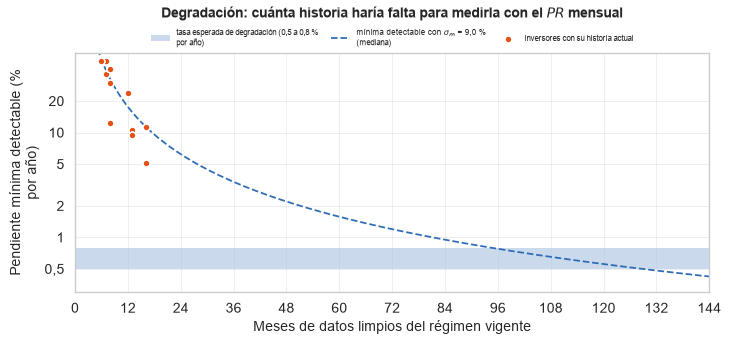

11 filas x 5 columnas; primeras 10:


,grupo,meses,sigma_m_pct,minima_detectable_pct_anio,anios_para_0_5
unidad,,,,,
P01I0102,G01,16,4.5236,5.1048,6.8001
P01I0202,G01,16,10.1231,11.3979,11.6341
P07I0101,G01,8,5.5566,12.3294,7.7994
P02I0102,G03,13,6.0641,10.4795,8.2674
P02I0202,G03,13,5.3748,9.5049,7.6284
P04I0102,G02,7,9.7452,47.7756,11.3427
P04I0202,G02,7,7.3787,36.2328,9.4228
P08I0101,G04,12,13.4670,23.8473,14.0725
P13I0101,G05,6,9.5861,47.8368,11.2189


En los 9 puntos de ERA5, la irradiación anual de 2015 a 2024 varía entre años con un coeficiente de variación de 1,7 a 2,2 %, y el año más apartado se separa de la media de 2,6 a 4,3 %: en el $Y_f$ anual, un solo año atípico del recurso equivale a 3 a 9 años de degradación. En el $PR$, que descuenta el recurso, los 11 inversores con historia suficiente tienen de 6 a 16 (mediana 8) meses válidos en su régimen vigente y una desviación mensual $\sigma_m$ de 4,5 a 13,7 (mediana 9,0) %. Con esa historia, la pendiente mínima detectable es de 5,1 a 47,8 (mediana 23,8) % por año, unas 30 a 48 veces la tasa esperada, y las pendientes ajustadas van de -36,8 a +6,0 % por año, valores sin sentido físico como degradación (la recta absorbe el ciclo estacional y los cambios de suciedad). Con la $\sigma_m$ medida, detectar 0,5 % por año exigiría de 6,8 a 14,2 (mediana 10,7) años de datos limpios, sin contar la autocorrelación ni el ciclo estacional.

Concluimos que la degradación no se puede estimar con esta historia y queda como línea futura. Además de años, hace falta un $PR$ menos ruidoso: sin piranómetro en sitio, el error de la irradiancia de satélite entra entero en el $PR$ mensual. Un modelo de referencia (por ejemplo, el global) podría servir de $PR_{base}$ para el método año contra año.

**Tiempo total: 0.5 min** en 14 celdas; memoria libre mínima 2.8 GB; memoria máxima del proceso 0.3 GB.

,celdas,segundos,memoria_proceso_max_gb,memoria_libre_min_gb,minutos,porcentaje
seccion,,,,,,
,14,29.11,0.32,2.77,0.49,100.0


**Las 15 celdas más lentas**

,n,seccion,primera_linea,segundos,memoria_proceso_gb,memoria_libre_gb,error,fin
13,14,,from scipy.stats import wilcoxon,4.75,0.24,2.77,False,2026-11-09 01:56:55
3,4,,"FAM = [(""ref__persistencia"", ""Persistencia""), ...",3.49,0.27,3.87,False,2026-11-09 01:56:33
10,11,,if not ERRORES.empty:,2.52,0.24,3.57,False,2026-11-09 01:56:46
12,13,,from scipy.stats import mannwhitneyu,2.40,0.24,3.39,False,2026-11-09 01:56:50
8,9,,SINTESIS = {,2.36,0.23,3.90,False,2026-11-09 01:56:43
5,6,,"for objetivo in (""yf"", ""pr""):",2.34,0.27,3.89,False,2026-11-09 01:56:37
2,3,,"def modelos_de(v, clave_prefijo):",2.11,0.22,3.91,False,2026-11-09 01:56:29
0,1,,filas = [],2.04,0.24,3.89,False,2026-11-09 01:56:27
7,8,,filas_f = [],1.90,0.32,3.84,False,2026-11-09 01:56:41
4,5,,"ABL_C = pd.DataFrame(R.get(""flota"", {}).get(""r...",1.79,0.23,3.91,False,2026-11-09 01:56:34


,celdas,segundos,memoria_proceso_max_gb,memoria_libre_min_gb,minutos,porcentaje
seccion,,,,,,
,14,29.11,0.32,2.77,0.49,100.0


In [17]:
import re
from tfm import pipeline
TASAS_DEGRADACION = (0.5, 0.8)            # % por año (Jordan y Kurtz, 2013)
def coma(v, d=1, signo=False):
    return (f"{v:+.{d}f}" if signo else f"{v:.{d}f}").replace(".", ",")
# Recurso: irradiación anual de ERA5 de 2015 a 2024 en el punto de cada localidad
filas_e = []
for g in LOC:
    try:
        era = pipeline.era5_climatologia(g)
    except Exception as error:            # sin la serie larga en la base: la localidad queda fuera de esta tabla
        display(Markdown(f"{g}: sin ERA5 de 2015 a 2024 ({error})."))
        continue
    s = era.set_index("datatime")["shortwave_radiation"]
    s = s[~s.index.duplicated()]
    s.index = s.index.tz_convert(config.ZONA)
    anual = s.groupby(s.index.year).agg(["sum", "count"])
    anual = anual[anual["count"] >= 0.99 * 8760]
    kwh = anual["sum"] / 1000.0
    if len(kwh) < 5:
        continue
    filas_e.append({"grupo": g, "anios": int(len(kwh)), "primer_anio": int(kwh.index.min()), "ultimo_anio": int(kwh.index.max()),
                    "media_kwh_m2": float(kwh.mean()), "cv_pct": float(100 * kwh.std() / kwh.mean()),
                    "mayor_desviacion_pct": float(100 * (kwh - kwh.mean()).abs().max() / kwh.mean())})
ERA_ANUAL = pd.DataFrame(filas_e).set_index("grupo") if filas_e else pd.DataFrame()
# Localidades que comparten la celda de ERA5 dan la misma serie: los resumenes cuentan puntos distintos
PUNTOS = ERA_ANUAL.drop_duplicates(subset=["media_kwh_m2", "cv_pct"]) if len(ERA_ANUAL) else ERA_ANUAL
display(Markdown(f"**Irradiación anual de ERA5** ({len(ERA_ANUAL)} localidades, {len(PUNTOS)} puntos distintos de la rejilla)"))
display(ERA_ANUAL.round(2))

# PR mensual del régimen vigente de cada inversor
filas_p = []
for g, v in LOC.items():
    for u in v.get("objetivos", {}):
        if not re.fullmatch(r"P\d{2}I\d{4}", u):          # solo inversores (las plantas los suman)
            continue
        ruta = config.DIR_INTERMEDIOS / g / f"objetivos_diarios_{u}.parquet"
        if not ruta.exists():
            continue
        d = pd.read_parquet(ruta)
        d = d[d["en_regimen"] & d["pr"].notna() & (d.index < pd.Timestamp(config.FIN_MODELADO))]
        m = d.groupby(d.index.to_period("M")).agg(yf=("yf", "sum"), yr=("yr", "sum"), dias=("pr", "size"))
        m = m[m["dias"] >= 20]
        fila = {"unidad": u, "grupo": g, "meses": int(len(m))}
        if len(m) >= 6:
            pr = m["yf"] / m["yr"]
            rel = 100 * pr / pr.mean()
            t = np.array([((p.start_time + (p.end_time - p.start_time) / 2) - m.index[0].start_time).days / 365.25 for p in m.index])
            X = np.column_stack([np.ones_like(t), t])
            beta = np.linalg.lstsq(X, rel.to_numpy(), rcond=None)[0]
            resid = rel.to_numpy() - X @ beta
            ee = float(np.sqrt((resid ** 2).sum() / (len(t) - 2) / ((t - t.mean()) ** 2).sum()))
            sigma = float(rel.std())
            fila.update({"desde": str(m.index[0]), "hasta": str(m.index[-1]), "pr_medio": float(pr.mean()), "sigma_m_pct": sigma,
                         "pendiente_pct_anio": float(beta[1]), "ee_pct_anio": ee, "minima_detectable_pct_anio": 1.96 * ee,
                         "anios_para_0_5": float((1.96 * sigma / TASAS_DEGRADACION[0]) ** (2 / 3))})
        filas_p.append(fila)
PR_MENSUAL = pd.DataFrame(filas_p).set_index("unidad") if filas_p else pd.DataFrame()
OK_P = PR_MENSUAL.dropna(subset=["sigma_m_pct"]) if "sigma_m_pct" in PR_MENSUAL else pd.DataFrame()
display(Markdown(f"**PR mensual del régimen vigente** ({len(OK_P)} de {len(PR_MENSUAL)} inversores con al menos 6 meses de 20 días válidos)"))
display(PR_MENSUAL.round(2))

if len(OK_P):
    f, ax = plt.subplots(figsize=(9, 4.2))
    meses_x = np.linspace(3, 144, 200)
    s_med = OK_P["sigma_m_pct"].median()
    ax.axhspan(*TASAS_DEGRADACION, color=config.COLOR_TENUE, alpha=0.6, lw=0, label="tasa esperada de degradación (0,5 a 0,8 % por año)")
    ax.plot(meses_x, 1.96 * s_med * (meses_x / 12) ** -1.5, color=config.COLOR_SECUNDARIO, ls="--", lw=1.6,
            label=f"mínima detectable con $\\sigma_m$ = {coma(s_med)} % (mediana)")
    ax.scatter(OK_P["meses"], OK_P["minima_detectable_pct_anio"], s=40, color=config.COLOR_PRINCIPAL, edgecolor="white", lw=1.5,
               zorder=3, label="inversores con su historia actual")
    ax.set_yscale("log")
    from matplotlib.ticker import NullFormatter
    ax.set_yticks([0.5, 1, 2, 5, 10, 20]); ax.set_yticklabels(["0,5", "1", "2", "5", "10", "20"])
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_ylim(0.3, max(30.0, 1.2 * float(OK_P["minima_detectable_pct_anio"].max())))
    ax.set_xlim(0, 144); ax.set_xticks(range(0, 145, 12))
    ax.set_xlabel("Meses de datos limpios del régimen vigente")
    ax.set_ylabel("Pendiente mínima detectable (% por año)")
    ax.set_title("Degradación: cuánta historia haría falta para medirla con el PR mensual")
    ax.legend(fontsize=8, loc="upper right")
    fig(f, "degradacion_detectable", OK_P[["grupo", "meses", "sigma_m_pct", "minima_detectable_pct_anio", "anios_para_0_5"]])

    def rango(col, d=1):
        return f"de {coma(OK_P[col].min(), d)} a {coma(OK_P[col].max(), d)} (mediana {coma(OK_P[col].median(), d)})"
    texto_era = (f"En los {len(PUNTOS)} puntos de ERA5, la irradiación anual de {int(ERA_ANUAL['primer_anio'].min())} a "
                 f"{int(ERA_ANUAL['ultimo_anio'].max())} varía entre años con un coeficiente de variación de "
                 f"{coma(PUNTOS['cv_pct'].min())} a {coma(PUNTOS['cv_pct'].max())} %, y el año más apartado se separa de la media "
                 f"de {coma(PUNTOS['mayor_desviacion_pct'].min())} a {coma(PUNTOS['mayor_desviacion_pct'].max())} %: en el $Y_f$ anual, "
                 f"un solo año atípico del recurso equivale a {PUNTOS['mayor_desviacion_pct'].min() / TASAS_DEGRADACION[1]:.0f} a "
                 f"{PUNTOS['mayor_desviacion_pct'].max() / TASAS_DEGRADACION[0]:.0f} años de degradación. " if len(PUNTOS) else "")
    display(Markdown(
        f"{texto_era}En el $PR$, que descuenta el recurso, los {len(OK_P)} inversores con historia suficiente tienen "
        f"{rango('meses', 0)} meses válidos en su régimen vigente y una desviación mensual $\\sigma_m$ {rango('sigma_m_pct')} %. "
        f"Con esa historia, la pendiente mínima detectable es {rango('minima_detectable_pct_anio')} % por año, unas "
        f"{OK_P['minima_detectable_pct_anio'].median() / TASAS_DEGRADACION[1]:.0f} a {OK_P['minima_detectable_pct_anio'].median() / TASAS_DEGRADACION[0]:.0f} "
        f"veces la tasa esperada, y las pendientes ajustadas van de {coma(OK_P['pendiente_pct_anio'].min(), signo=True)} a {coma(OK_P['pendiente_pct_anio'].max(), signo=True)} % por año, "
        f"valores sin sentido físico como degradación (la recta absorbe el ciclo estacional y los cambios de suciedad). Con la "
        f"$\\sigma_m$ medida, detectar 0,5 % por año exigiría {rango('anios_para_0_5')} años de datos limpios, sin contar la "
        f"autocorrelación ni el ciclo estacional.\n\nConcluimos que la degradación no se puede estimar con esta historia y queda "
        f"como línea futura. Además de años, hace falta un $PR$ menos ruidoso: sin piranómetro en sitio, el error de la "
        f"irradiancia de satélite entra entero en el $PR$ mensual. Un modelo de referencia (por ejemplo, el global) podría "
        f"servir de $PR_{{base}}$ para el método año contra año."))
    res.registrar("comparacion.degradacion", {
        "tasas_esperadas_pct_anio": list(TASAS_DEGRADACION),
        "era5": ERA_ANUAL.round(3).to_dict(orient="index"),
        "era5_resumen": {"puntos": int(len(PUNTOS)), "cv_min_pct": float(PUNTOS["cv_pct"].min()), "cv_max_pct": float(PUNTOS["cv_pct"].max()),
                         "cv_mediana_pct": float(PUNTOS["cv_pct"].median()),
                         "mayor_desviacion_min_pct": float(PUNTOS["mayor_desviacion_pct"].min()),
                         "mayor_desviacion_max_pct": float(PUNTOS["mayor_desviacion_pct"].max())} if len(PUNTOS) else {},
        "unidades": PR_MENSUAL.round(4).replace({np.nan: None}).to_dict(orient="index"),
        "resumen": {"inversores": int(len(OK_P)), "inversores_sin_historia": int(len(PR_MENSUAL) - len(OK_P)),
                    **{f"{c}_{e}": float(getattr(OK_P[c], e)()) for c in ("meses", "sigma_m_pct", "minima_detectable_pct_anio",
                                                                         "anios_para_0_5", "pendiente_pct_anio")
                       for e in ("min", "median", "max")}}})
else:
    display(Markdown("Ningún inversor tiene todavía 6 meses con 20 días válidos en su régimen vigente."))
tiempos.reporte()